# Portfolio Performance Evaluation
### Three-asset algorithmic portfolio · evaluation period 1–20 October 2026

This notebook evaluates the out-of-sample performance of a three-asset algorithmic portfolio
over the evaluation window, at the portfolio level and for each strategy sleeve. 

| Sleeve | Instrument | Strategy | Direction | Decision interval |
|---|---|---|---|---|
| **SPY** | SPDR S&P 500 ETF (`spy_usd`) | Momentum: EMA(8) / EMA(16) trend filter with an 8-bar trailing-return gate (enter > 0.25%, exit ≤ 0%) | Long / cash | 2 hours |
| **STI** | SPDR STI ETF, ES3.SI (`sti_es3_sgd`) | Mean reversion: 16-bar rolling z-score (enter ≤ −1.25σ, exit ≥ +0.25σ, 4–20 bar holding, 4-bar cooldown) | Long / cash | 2 hours |
| **BTC** | Bitcoin / USDT (`btc_usdt`) | Machine learning: LightGBM up/down probability models as a volatility gauge, combined with a weighted indicator vote | Long / short | 30 minutes |

**Portfolio construction.** USD 500,000 initial capital, traded through a single USD cash ledger.
Sleeve budgets are set on 1 October by capped inverse volatility of each strategy's after-cost
returns over the prior 60 days: 95% gross target, STI capped at 10%, SPY and BTC at 75%, and 5% held
as strategic cash. When at least two sleeves are materially active, idle capital may scale active
targets up to 2× within the caps.

**Evaluation conventions.** Execution at the next eligible bar open; valuation at raw closes,
converted point-in-time to USD; broker commissions as per `config/cost_assumptions.json`. Risk
metrics use UTC daily returns with the partial final day excluded, 365-day annualisation, CAGR on
elapsed calendar time, and the U.S. Treasury 3-month yield as the risk-free rate. All times are UTC.

## 1. Setup

In [1]:
from __future__ import annotations

import json
import math
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator, PercentFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

# This notebook lives in performance_evaluation/, which sits inside the repository root.
# Frozen inputs and outputs are read from performance_evaluation/results/; shared code and
# configuration are imported from the repository root; market data comes from the separately
# submitted Data/ folder placed next to the repository folder.
EVAL_DIR = Path.cwd() if (Path.cwd() / "portfolio_performance_evaluation.ipynb").is_file() else Path.cwd() / "performance_evaluation"
PROJECT_ROOT = EVAL_DIR.parent
DATA_DIR = PROJECT_ROOT.parent / "Data"
RESULTS = EVAL_DIR / "results" / "portfolio_simulation"
FIG_DIR = EVAL_DIR / "results" / "eda_notebook"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for p in (PROJECT_ROOT, PROJECT_ROOT / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src import metrics as M
from src.risk_free import load_treasury_annual_rates

START, END = "2026-10-01", "2026-10-21"   # evaluation window; END exclusive
SAVE_FIGURES = True

ASSETS = ["spy_usd", "sti_es3_sgd", "btc_usdt"]
LABEL = {"spy_usd": "SPY · Momentum", "sti_es3_sgd": "STI · Mean reversion", "btc_usdt": "BTC · ML voting"}
SHORT = {"spy_usd": "SPY", "sti_es3_sgd": "STI", "btc_usdt": "BTC"}
COLOR = {"spy_usd": "#2a78d6", "sti_es3_sgd": "#eb6834", "btc_usdt": "#1baf7a"}
INK, INK2, MUTED, GRID, SURF, MID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb", "#f0efec"
POS, NEG = "#2a78d6", "#e34948"
DIVERGING = LinearSegmentedColormap.from_list("div", [NEG, MID, POS])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6, "font.size": 10,
    "figure.dpi": 100, "text.parse_math": False,
})


def money(v: float, dp: int = 0) -> str:
    return f"-${abs(v):,.{dp}f}" if v < 0 else f"${v:,.{dp}f}"


USD = FuncFormatter(lambda v, _: money(v))
PCT = lambda d=1: PercentFormatter(xmax=1, decimals=d)  # noqa: E731


def date_axis(ax, every=2):
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=every))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def end_label(ax, x, y, text, color, dy=0):
    ax.plot([x], [y], "o", ms=4, color=color, zorder=6)
    ax.annotate(text, (x, y), xytext=(6, dy), textcoords="offset points", va="center",
                fontsize=8.5, color=INK2)

## 2. Data

### 2.1 Simulation outputs and market data
Equity curve, decisions, fills and completed trades from the frozen simulation; the BTC strategy's
exported targets and model diagnostics; 30-minute market bars; the submitted daily closing prices;
and the 3-month Treasury yield used as the risk-free rate.

In [2]:
def utc(s):
    return pd.to_datetime(s, utc=True, format="mixed")


curve = pd.read_csv(RESULTS / "equity_curve.csv")
curve["timestamp"] = utc(curve["timestamp"])
curve = curve.set_index("timestamp").sort_index()
decisions = pd.read_csv(RESULTS / "decisions.csv")
decisions["timestamp"] = utc(decisions["timestamp"])
fills = pd.read_csv(RESULTS / "fills.csv")
fills["timestamp"] = utc(fills["timestamp"])
trades = pd.read_csv(RESULTS / "trades.csv")
for c in ("entry_time", "exit_time"):
    trades[c] = utc(trades[c])
trades["holding_period"] = trades["exit_time"] - trades["entry_time"]
trades["holding_hours"] = trades["holding_period"].dt.total_seconds() / 3600
summary = pd.read_csv(RESULTS / "performance_summary.csv").iloc[0]
risk_weights = pd.read_csv(RESULTS / "risk_weights.csv").iloc[0]
vol_diag = pd.read_csv(RESULTS / "volatility_diagnostics.csv")
manifest = json.loads((RESULTS / "simulation_manifest.json").read_text())

btc = pd.read_csv(EVAL_DIR / "results/btc_target_exports/btc_targets.csv")
btc["bar_open_time_utc"] = utc(btc["bar_open_time_utc"])
btc = btc.set_index("bar_open_time_utc").sort_index()

BAR_COLS = ["instrument_id", "bar_open_time_utc", "session_date_local", "open", "high", "low", "close",
            "adjusted_close", "volume", "is_final", "bar_origin", "quality_status"]
canon_path = PROJECT_ROOT / "data/canonical/market_bars_30m_simulation_live_to_date.csv"
bars = (pd.read_csv(canon_path, low_memory=False, usecols=BAR_COLS) if canon_path.exists()
        else pd.read_excel(DATA_DIR / "market_bars_30m_simulation.xlsx", usecols=BAR_COLS))
bars["bar_open_time_utc"] = utc(bars["bar_open_time_utc"])
daily_close = pd.read_excel(DATA_DIR / "asset_daily_closing_prices.xlsx")
daily_close["date"] = pd.to_datetime(daily_close["date"])

INITIAL = float(manifest["initial_cash_base"])
RF = float(summary["Average Annual Risk-Free Rate"])
RF_SERIES = load_treasury_annual_rates(PROJECT_ROOT / "data/risk_free/raw/us_treasury_yield_curve_2026.csv")
t0, t1 = pd.Timestamp(START, tz="UTC"), pd.Timestamp(END, tz="UTC")
idx = curve.index
equity = curve["equity"].astype(float)
print(f"Evaluation window : {idx[0]:%d %b %Y %H:%M} to {idx[-1]:%d %b %Y %H:%M} UTC ({len(idx)} bars)")
print(f"Equity            : {money(INITIAL)} -> {money(equity.iloc[-1])} ({equity.iloc[-1] / INITIAL - 1:+.2%})")
print(f"Activity          : {len(fills)} orders, {len(trades)} completed round trips")
print(f"Risk-free rate    : {RF:.2%} average (U.S. Treasury 3-month)")

Evaluation window : 01 Oct 2026 00:00 to 20 Oct 2026 23:30 UTC (960 bars)
Equity            : $500,000 -> $507,084 (+1.42%)
Activity          : 57 orders, 24 completed round trips
Risk-free rate    : 4.23% average (U.S. Treasury 3-month)


### 2.2 Derived series
Mark-to-market P&L per sleeve is the cumulative execution cash flow (−quantity × fill price − fee)
plus position × USD close. The sleeves reconcile exactly to portfolio equity less initial capital.
Benchmarks are frictionless buy-and-hold positions entered at each asset's first open in the window.

In [3]:
close_usd = (decisions.pivot_table(index="timestamp", columns="instrument_id", values="close_usd", aggfunc="last")
             .reindex(idx).ffill())
first_open = decisions.sort_values("timestamp").groupby("instrument_id")["open_usd"].first()
pos = pd.DataFrame({a: curve[f"pos_{a}"] for a in ASSETS}).fillna(0.0)
mkt_value = (pos * close_usd[ASSETS]).fillna(0.0)


def cum_on_index(values: pd.Series, times: pd.Series) -> pd.Series:
    s = values.groupby(times).sum().cumsum()
    return s.reindex(idx.union(s.index)).sort_index().ffill().reindex(idx).fillna(0.0)


cash_flow, cum_cost = {}, {}
for a in ASSETS:
    f = fills[fills["asset"].eq(a)]
    cash_flow[a] = cum_on_index(-(f["qty"] * f["price"]) - f["fee"], f["timestamp"])
    cum_cost[a] = cum_on_index(f["total_cost"], f["timestamp"])
pnl = pd.DataFrame(cash_flow) + mkt_value
cum_cost = pd.DataFrame(cum_cost)
weights = mkt_value.div(equity, axis=0)
gap = (equity - INITIAL - pnl.sum(axis=1)).abs().max()
print(f"Reconciliation difference (equity vs sum of sleeve P&L): {money(gap, 4)}")

# Frictionless buy-and-hold indices from each asset's first open in the window
bh = pd.DataFrame({a: close_usd[a] / first_open[a] for a in ASSETS}).fillna(1.0)
sleeve_w = {a: float(risk_weights[a]) for a in ASSETS}
sleeve_cap = {a: sleeve_w[a] * INITIAL for a in ASSETS}

T0 = idx[0] - pd.Timedelta(nanoseconds=1)


def with_start(s: pd.Series, v: float) -> pd.Series:
    return pd.concat([pd.Series([v], index=[T0]), s])


series = {
    "Portfolio": with_start(equity, INITIAL),
    "Portfolio before costs": with_start(equity + cum_cost.sum(axis=1), INITIAL),
    "Same weights, buy & hold": with_start(INITIAL * (1 - sum(sleeve_w.values()))
                                           + sum(sleeve_cap[a] * bh[a] for a in ASSETS), INITIAL),
    "Equal-weight buy & hold": with_start(INITIAL * bh.mean(axis=1), INITIAL),
}
for a in ASSETS:
    series[f"{SHORT[a]} buy & hold"] = with_start(INITIAL * bh[a], INITIAL)
for a in ASSETS:
    series[f"{SHORT[a]} sleeve"] = with_start(sleeve_cap[a] + pnl[a], sleeve_cap[a])
r30 = equity.pct_change().fillna(equity.iloc[0] / INITIAL - 1)   # 30-minute portfolio returns

Reconciliation difference (equity vs sum of sleeve P&L): $0.0000


## 3. Market context
Daily closes (USD) from the submitted closing-price file: SPY at 20:00 UTC, STI at 09:00 UTC and
BTC at 00:00 UTC on the following day.

In [4]:
%pip install jinja2


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /tmp/claude-0/-home-claude/1d0d6acf-57fe-5bbf-9b95-bda4c01f91a0/scratchpad/venv/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


instrument_id,spy_usd,sti_es3_sgd,btc_usdt
date,,,
2026-10-01 00:00:00,764.03,4.50,"84,880.05"
2026-10-02 00:00:00,769.65,4.46,"84,518.01"
2026-10-03 00:00:00,nan,nan,"84,753.56"
2026-10-04 00:00:00,nan,nan,"86,530.00"
2026-10-05 00:00:00,774.90,4.50,"85,766.87"
2026-10-06 00:00:00,779.14,4.51,"85,549.93"
2026-10-07 00:00:00,777.17,4.47,"83,321.81"
2026-10-08 00:00:00,773.89,4.30,"81,754.45"
2026-10-09 00:00:00,778.53,4.28,"82,635.55"


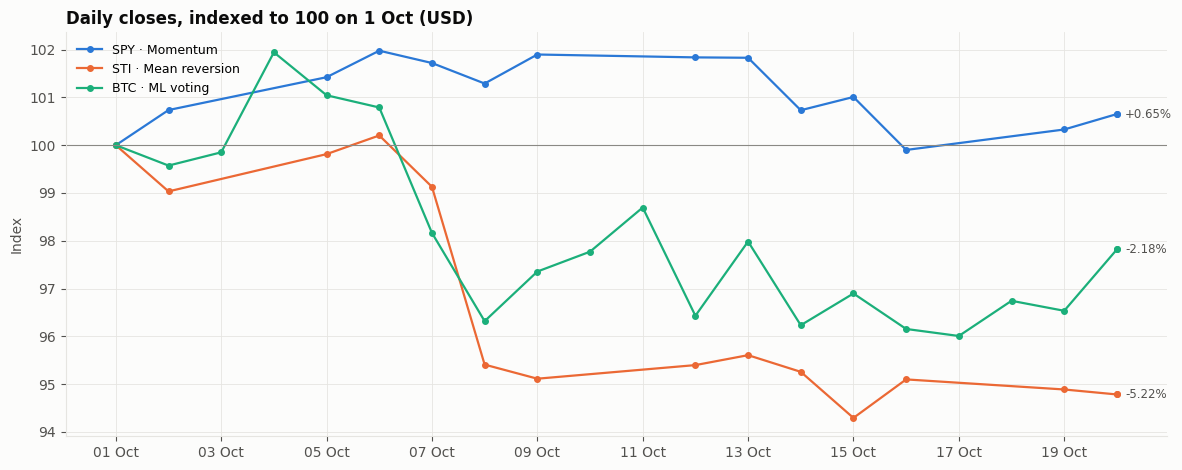

Close-to-close change over the window: SPY +0.65%, STI -5.22%, BTC -2.18%


In [5]:
dc = daily_close.pivot_table(index="date", columns="instrument_id", values="close_usd")[ASSETS]
display(dc.style.format("{:,.2f}").set_caption("Daily closing prices (USD)"))

fig, ax = plt.subplots(figsize=(12, 4.8))
for a in ASSETS:
    s = dc[a].dropna()
    norm = 100 * s / s.iloc[0]
    ax.plot(norm.index, norm, marker="o", ms=4, color=COLOR[a], label=LABEL[a])
    end_label(ax, norm.index[-1], norm.iloc[-1], f"{norm.iloc[-1] - 100:+.2f}%", COLOR[a])
ax.axhline(100, color=MUTED, lw=0.8)
ax.set_title("Daily closes, indexed to 100 on 1 Oct (USD)")
ax.set_ylabel("Index")
ax.legend(loc="upper left")
date_axis(ax)
fig.tight_layout(); save(fig, "03a_daily_closes_indexed"); plt.show()

chg = dc.apply(lambda s: s.dropna().iloc[-1] / s.dropna().iloc[0] - 1)
print("Close-to-close change over the window:", ", ".join(f"{SHORT[a]} {chg[a]:+.2%}" for a in ASSETS))

**Trading sessions.** SPY trades in the US session (13:30–20:00 UTC), STI in the Singapore session
(01:00–09:00 UTC, with a lunch break) and BTC continuously. Weekend and overnight exposure is
therefore carried by the BTC sleeve alone.

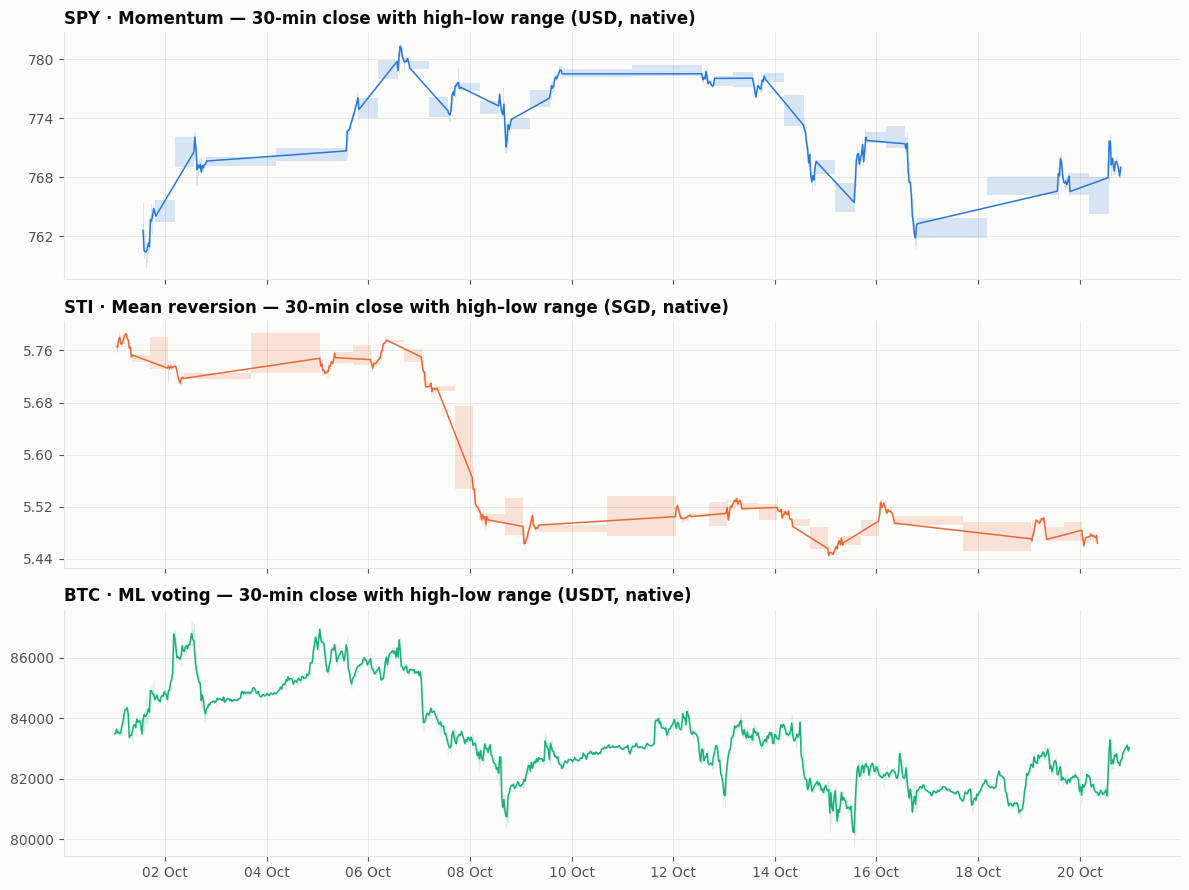

In [6]:
oct_bars = bars[(bars["bar_open_time_utc"] >= t0) & (bars["bar_open_time_utc"] < t1)].copy()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, a in zip(axes, ASSETS):
    b = oct_bars[oct_bars["instrument_id"].eq(a)].set_index("bar_open_time_utc")
    ax.plot(b.index, b["close"], color=COLOR[a], lw=1.1)
    ax.fill_between(b.index, b["low"], b["high"], color=COLOR[a], alpha=0.18, lw=0, step="mid")
    ccy = {"spy_usd": "USD", "sti_es3_sgd": "SGD", "btc_usdt": "USDT"}[a]
    ax.set_title(f"{LABEL[a]} — 30-min close with high–low range ({ccy}, native)")
    ax.yaxis.set_major_locator(MaxNLocator(5))
date_axis(axes[-1])
fig.tight_layout(); save(fig, "03b_intraday_prices"); plt.show()

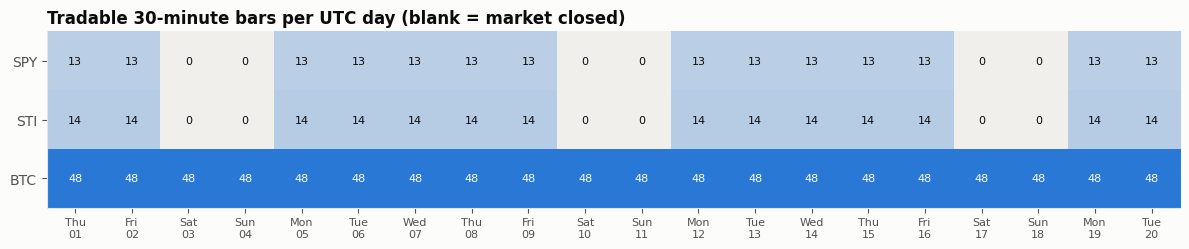

In [7]:
cov = (oct_bars.assign(day=oct_bars["bar_open_time_utc"].dt.date)
       .pivot_table(index="instrument_id", columns="day", values="close", aggfunc="count")
       .reindex(ASSETS).fillna(0))
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(cov.values, aspect="auto", cmap=LinearSegmentedColormap.from_list("seq", [MID, "#2a78d6"]))
ax.grid(False)
ax.set_yticks(range(3), [SHORT[a] for a in ASSETS])
ax.set_xticks(range(cov.shape[1]), [pd.Timestamp(d).strftime("%a\n%d") for d in cov.columns], fontsize=8)
for i in range(3):
    for j in range(cov.shape[1]):
        v = int(cov.iat[i, j])
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > 30 else INK)
ax.set_title("Tradable 30-minute bars per UTC day (blank = market closed)")
fig.tight_layout(); save(fig, "03c_bar_coverage"); plt.show()

**Volatility and co-movement.** Realised volatility and correlation of the assets' daily returns over
the window.

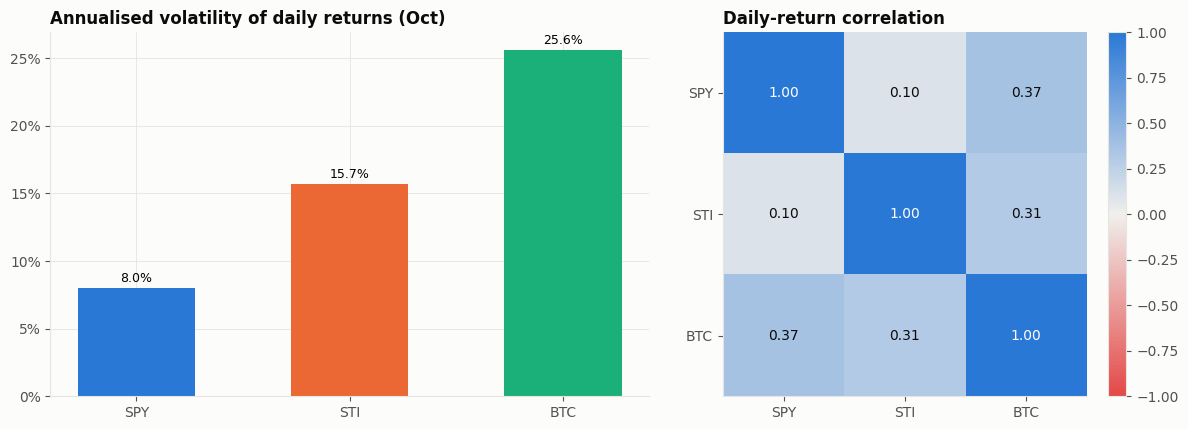

In [8]:
dr = dc.pct_change()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
vol = dr.std() * np.sqrt([252, 252, 365])
ax.bar([SHORT[a] for a in ASSETS], vol.values, color=[COLOR[a] for a in ASSETS], width=0.55)
for i, v in enumerate(vol.values):
    ax.annotate(f"{v:.1%}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PCT(0))
ax.set_title("Annualised volatility of daily returns (Oct)")
corr = dr.corr()
im = ax2.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax2.grid(False)
ax2.set_xticks(range(3), [SHORT[a] for a in ASSETS]); ax2.set_yticks(range(3), [SHORT[a] for a in ASSETS])
for i in range(3):
    for j in range(3):
        ax2.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=10,
                 color="white" if abs(corr.iat[i, j]) > 0.6 else INK)
ax2.set_title("Daily-return correlation")
fig.colorbar(im, ax=ax2, fraction=0.046)
fig.tight_layout(); save(fig, "03d_asset_vol_corr"); plt.show()

## 4. Signal generation by strategy
Indicators are recomputed with the project's strategy functions on the same decision bars used in
the simulation and overlaid with the positions actually held. A signal is known at a decision bar's
close and executed at the next bar's open.

In [9]:
from trading_strategy import (MeanReversionParameters, MomentumParameters,
                              generate_mean_reversion_signals, generate_momentum_signals)
from trading_strategy.common import prepare_strategy_bars

strat_cfg = json.loads((PROJECT_ROOT / "config/selected_strategies.json").read_text())["assets"]


def decision_bars(asset_bars: pd.DataFrame, minutes: int) -> pd.DataFrame:
    """Same 2-hour block sampling as portfolio_simulation._rule_based_signal."""
    prepared = prepare_strategy_bars(asset_bars)
    factor = minutes // 30
    d = prepared.copy()
    gap_ = d.groupby("instrument_id")["bar_open_time_utc"].diff()
    seg = gap_.ne(pd.Timedelta(minutes=30))
    seg |= d.groupby("instrument_id")["session_date_local"].transform(lambda v: v.ne(v.shift()))
    d["_seg"] = seg.groupby(d["instrument_id"]).cumsum()
    d["_blk"] = d.groupby(["instrument_id", "_seg"]).cumcount() // factor
    return d.groupby(["instrument_id", "_seg", "_blk"]).tail(1).drop(columns=["_seg", "_blk"]).reset_index(drop=True)


def strategy_frame(a):
    b = bars[bars["instrument_id"].eq(a) & (bars["bar_open_time_utc"] < t1)]
    db = decision_bars(b, strat_cfg[a]["decision_interval_minutes"])
    if strat_cfg[a]["strategy"] == "momentum":
        s = generate_momentum_signals(db, MomentumParameters(**strat_cfg[a]["parameters"]))
    else:
        s = generate_mean_reversion_signals(db, MeanReversionParameters(**strat_cfg[a]["parameters"]))
    return s.set_index("bar_open_time_utc")


def shade_positions(ax, a, lo, hi):
    p = pos[a]
    ax.fill_between(p.index, lo, hi, where=p > 0, step="post", color=COLOR[a], alpha=0.13, lw=0, label="Long held")
    if (p < 0).any():
        ax.fill_between(p.index, lo, hi, where=p < 0, step="post", color=NEG, alpha=0.13, lw=0, label="Short held")


def mark_fills(ax, a):
    f = fills[fills["asset"].eq(a)]
    b, s = f[f["qty"] > 0], f[f["qty"] < 0]
    ax.scatter(b["timestamp"], b["ref_price"], marker="^", s=70, color=POS, edgecolor=SURF, lw=1.2, zorder=6, label=f"Buy ({len(b)})")
    ax.scatter(s["timestamp"], s["ref_price"], marker="v", s=70, color=NEG, edgecolor=SURF, lw=1.2,
               zorder=6, label=f"Sell ({len(s)})")

### 4.1 SPY — momentum
Entry requires the fast EMA above the slow EMA and an 8-bar trailing return above +0.25%; exit occurs
when either condition fails. The number of orders exceeds the number of round trips because held
positions are resized when the active-capital scaling multiplier changes.

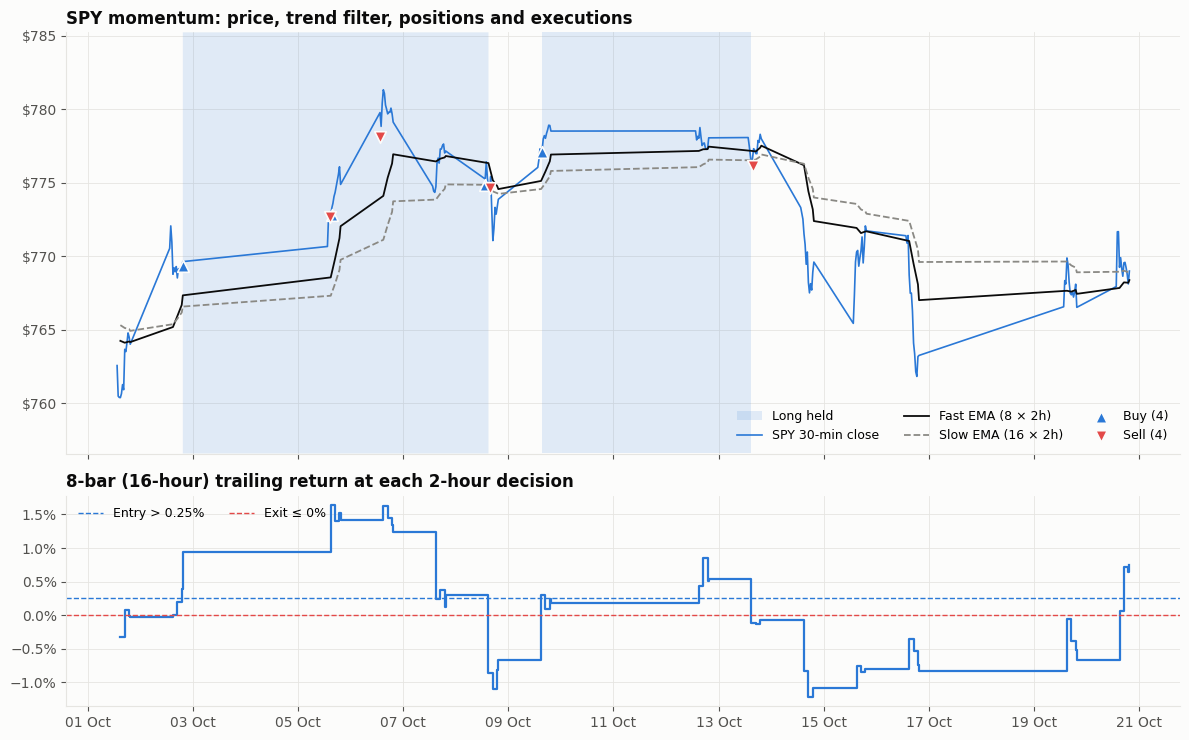

,signal,signal_reason,adjusted_close,momentum_return
bar_open_time_utc,,,,
2026-10-02 19:00:00+00:00,BUY,momentum_entry,769.35,+0.393%
2026-10-08 15:00:00+00:00,SELL,momentum_exit,774.66,-0.855%
2026-10-09 15:00:00+00:00,BUY,momentum_entry,777.08,+0.301%
2026-10-13 15:00:00+00:00,SELL,momentum_exit,776.17,-0.117%


In [10]:
a = "spy_usd"
sf = strategy_frame(a).loc[t0 - pd.Timedelta(days=3):]
px = decisions[decisions["instrument_id"].eq(a)].set_index("timestamp")["close_usd"]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
lo, hi = px.min() * 0.995, px.max() * 1.005
shade_positions(ax, a, lo, hi)
ax.plot(px.index, px, color=COLOR[a], lw=1.2, label="SPY 30-min close")
w = sf.loc[t0:]
ax.plot(w.index, w["momentum_fast_ema"], color=INK, lw=1.3, label="Fast EMA (8 × 2h)")
ax.plot(w.index, w["momentum_slow_ema"], color=MUTED, lw=1.3, ls="--", label="Slow EMA (16 × 2h)")
mark_fills(ax, a)
ax.set_ylim(lo, hi)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_title("SPY momentum: price, trend filter, positions and executions")
ax.legend(ncol=3, loc="lower right")
ax2.plot(w.index, w["momentum_return"], color=COLOR[a], drawstyle="steps-post")
p_ = strat_cfg[a]["parameters"]
ax2.axhline(p_["entry_threshold"], color=POS, ls="--", lw=1, label=f"Entry > {p_['entry_threshold']:.2%}")
ax2.axhline(p_["exit_threshold"], color=NEG, ls="--", lw=1, label=f"Exit ≤ {p_['exit_threshold']:.0%}")
ax2.yaxis.set_major_formatter(PCT(1))
ax2.set_title("8-bar (16-hour) trailing return at each 2-hour decision")
ax2.legend(loc="upper left", ncol=2)
date_axis(ax2)
fig.tight_layout(); save(fig, "04a_spy_momentum"); plt.show()
ev = sf.loc[t0:][sf.loc[t0:]["signal"].isin(["BUY", "SELL"])][["signal", "signal_reason", "adjusted_close",
                                                                   "momentum_return"]]
display(ev.style.format({"adjusted_close": "{:,.2f}", "momentum_return": "{:+.3%}"})
        .set_caption("SPY decision-bar signals in the window"))

### 4.2 STI — mean reversion
Entry when the 16-bar z-score falls to −1.25 or below; exit when it recovers to +0.25 after at
least 4 bars, or after a maximum of 20 bars, followed by a 4-bar cooldown.

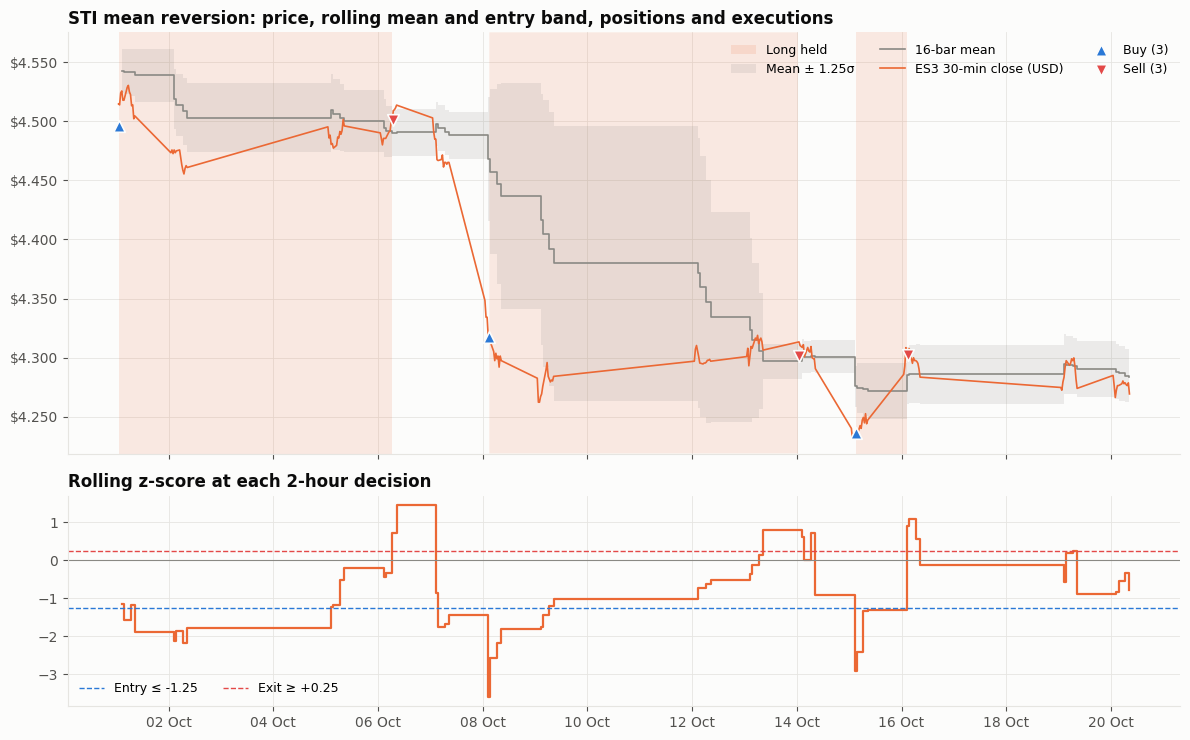

,signal,signal_reason,adjusted_close,mean_reversion_z_score
bar_open_time_utc,,,,
2026-10-06 06:30:00+00:00,SELL,mean_reversion_exit,5.760,+0.70
2026-10-08 02:30:00+00:00,BUY,mean_reversion_entry,5.526,-3.59
2026-10-13 08:30:00+00:00,SELL,mean_reversion_exit,5.517,+0.79
2026-10-15 02:30:00+00:00,BUY,mean_reversion_entry,5.450,-2.91
2026-10-16 02:30:00+00:00,SELL,mean_reversion_exit,5.519,+0.90


In [11]:
a = "sti_es3_sgd"
sf = strategy_frame(a).loc[t0 - pd.Timedelta(days=3):]
w = sf.loc[t0:]
rate = decisions[decisions["instrument_id"].eq(a)].set_index("timestamp")["rate_to_usd"]
rate_w = rate.reindex(w.index, method="ffill").bfill()
px = decisions[decisions["instrument_id"].eq(a)].set_index("timestamp")["close_usd"]
p_ = strat_cfg[a]["parameters"]
mean_usd = w["mean_reversion_average"] * rate_w
band = w["mean_reversion_std"] * rate_w * abs(p_["entry_z_score"])
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
lo, hi = min(px.min(), (mean_usd - band).min()) * 0.997, max(px.max(), (mean_usd + band).max()) * 1.003
shade_positions(ax, a, lo, hi)
ax.fill_between(w.index, mean_usd - band, mean_usd + band, step="post", color=MUTED, alpha=0.15, lw=0,
                label="Mean ± 1.25σ")
ax.plot(w.index, mean_usd, color=MUTED, lw=1.2, drawstyle="steps-post", label="16-bar mean")
ax.plot(px.index, px, color=COLOR[a], lw=1.2, label="ES3 30-min close (USD)")
mark_fills(ax, a)
ax.set_ylim(lo, hi)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.3f}"))
ax.set_title("STI mean reversion: price, rolling mean and entry band, positions and executions")
ax.legend(ncol=3, loc="upper right")
ax2.plot(w.index, w["mean_reversion_z_score"], color=COLOR[a], drawstyle="steps-post")
ax2.axhline(p_["entry_z_score"], color=POS, ls="--", lw=1, label=f"Entry ≤ {p_['entry_z_score']}")
ax2.axhline(p_["exit_z_score"], color=NEG, ls="--", lw=1, label=f"Exit ≥ +{p_['exit_z_score']}")
ax2.axhline(0, color=MUTED, lw=0.8)
ax2.set_title("Rolling z-score at each 2-hour decision")
ax2.legend(loc="lower left", ncol=2)
date_axis(ax2)
fig.tight_layout(); save(fig, "04b_sti_mean_reversion"); plt.show()
ev = w[w["signal"].isin(["BUY", "SELL"])][["signal", "signal_reason", "adjusted_close", "mean_reversion_z_score"]]
display(ev.style.format({"adjusted_close": "{:,.3f}", "mean_reversion_z_score": "{:+.2f}"})
        .set_caption("STI decision-bar signals in the window"))

### 4.3 BTC — machine-learning voting strategy
Two LightGBM classifiers estimate the probability of a move larger than one standard deviation up
(`p_up`) and down (`p_down`) over the next 12 bars; their sum acts as a volatility gauge. A full-size
entry requires a gauge of at least 0.35 and a weighted indicator vote (Bollinger %B, stochastic,
12-bar return, volume z-score) of |score| ≥ 2. If no entry occurs during a day, a 10% fallback
position is opened at 20:00 UTC in the direction of the vote and held for 12 bars.

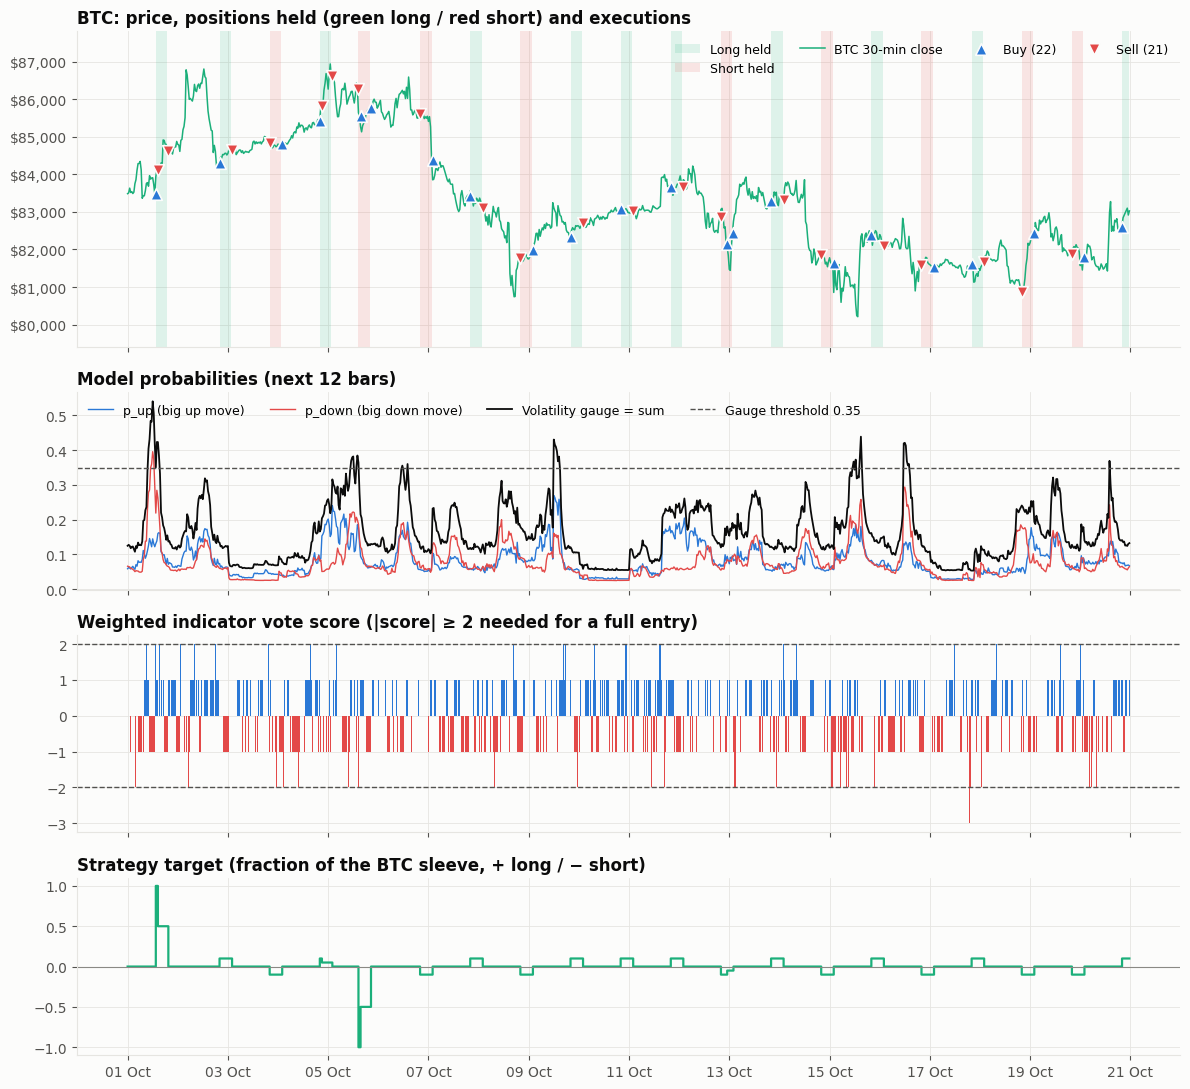

Bars with gauge ≥ 0.35: 3.9%;  bars with |vote| ≥ 2: 5.1%;  bars where both hold: 0.2%


In [12]:
bw = btc.loc[t0:t1 - pd.Timedelta(minutes=1)]
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.6, 1, 1, 0.9]})
ax = axes[0]
px = decisions[decisions["instrument_id"].eq("btc_usdt")].set_index("timestamp")["close_usd"]
lo, hi = px.min() * 0.99, px.max() * 1.01
shade_positions(ax, "btc_usdt", lo, hi)
ax.plot(px.index, px, color=COLOR["btc_usdt"], lw=1.1, label="BTC 30-min close")
mark_fills(ax, "btc_usdt")
ax.set_ylim(lo, hi)
ax.yaxis.set_major_formatter(USD)
ax.set_title("BTC: price, positions held (green long / red short) and executions")
ax.legend(ncol=4, loc="upper right")

ax = axes[1]
ax.plot(bw.index, bw["p_up"], color=POS, lw=1, label="p_up (big up move)")
ax.plot(bw.index, bw["p_down"], color=NEG, lw=1, label="p_down (big down move)")
gauge = bw["p_up"] + bw["p_down"]
ax.plot(bw.index, gauge, color=INK, lw=1.3, label="Volatility gauge = sum")
ax.axhline(0.35, color=INK2, ls="--", lw=1, label="Gauge threshold 0.35")
ax.set_title("Model probabilities (next 12 bars)")
ax.legend(ncol=4, loc="upper left")

ax = axes[2]
ax.bar(bw.index, bw["vote_score"], width=0.02, color=np.where(bw["vote_score"] >= 0, POS, NEG))
for y in (2, -2):
    ax.axhline(y, color=INK2, ls="--", lw=1)
ax.set_title("Weighted indicator vote score (|score| ≥ 2 needed for a full entry)")

ax = axes[3]
ax.step(bw.index, bw["execution_target_position"], where="post", color=COLOR["btc_usdt"])
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_title("Strategy target (fraction of the BTC sleeve, + long / − short)")
date_axis(ax)
fig.tight_layout(); save(fig, "04c_btc_ml_voting"); plt.show()
print(f"Bars with gauge ≥ 0.35: {(gauge >= 0.35).mean():.1%};  bars with |vote| ≥ 2: {(bw['vote_score'].abs() >= 2).mean():.1%};"
      f"  bars where both hold: {((gauge >= 0.35) & (bw['vote_score'].abs() >= 2)).mean():.1%}")

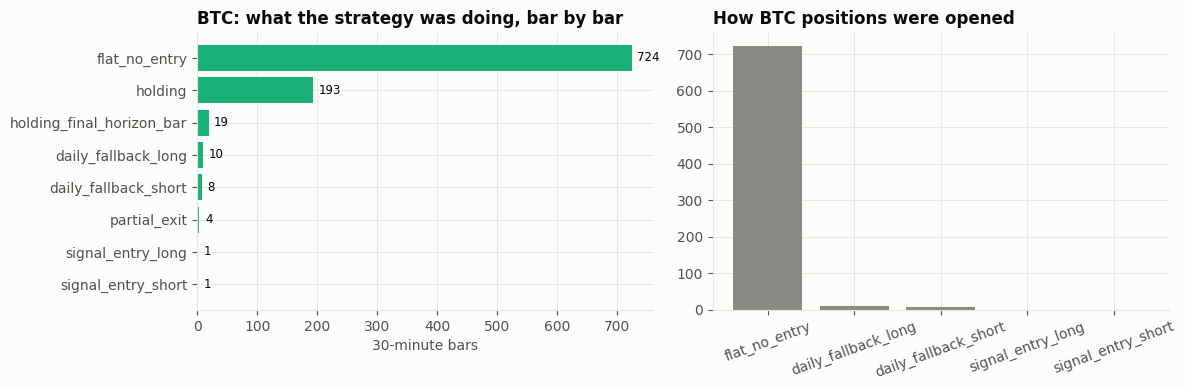

In [13]:
reasons = bw["signal_reason"].value_counts()
entries = bw[bw["signal_reason"].str.contains("entry|fallback")]["signal_reason"].value_counts()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax.barh(reasons.index[::-1], reasons.values[::-1], color=COLOR["btc_usdt"])
ax.set_title("BTC: what the strategy was doing, bar by bar")
ax.set_xlabel("30-minute bars")
for i, v in enumerate(reasons.values[::-1]):
    ax.annotate(str(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5)
ax2.bar(entries.index, entries.values, color=[COLOR["btc_usdt"] if "signal" in i else MUTED for i in entries.index])
ax2.set_title("How BTC positions were opened")
ax2.tick_params(axis="x", rotation=20)
fig.tight_layout(); save(fig, "04d_btc_reasons"); plt.show()

### 4.4 Signal timeline
Executed targets of each sleeve as a fraction of its budget, and the number of sleeves active at
each point in time.

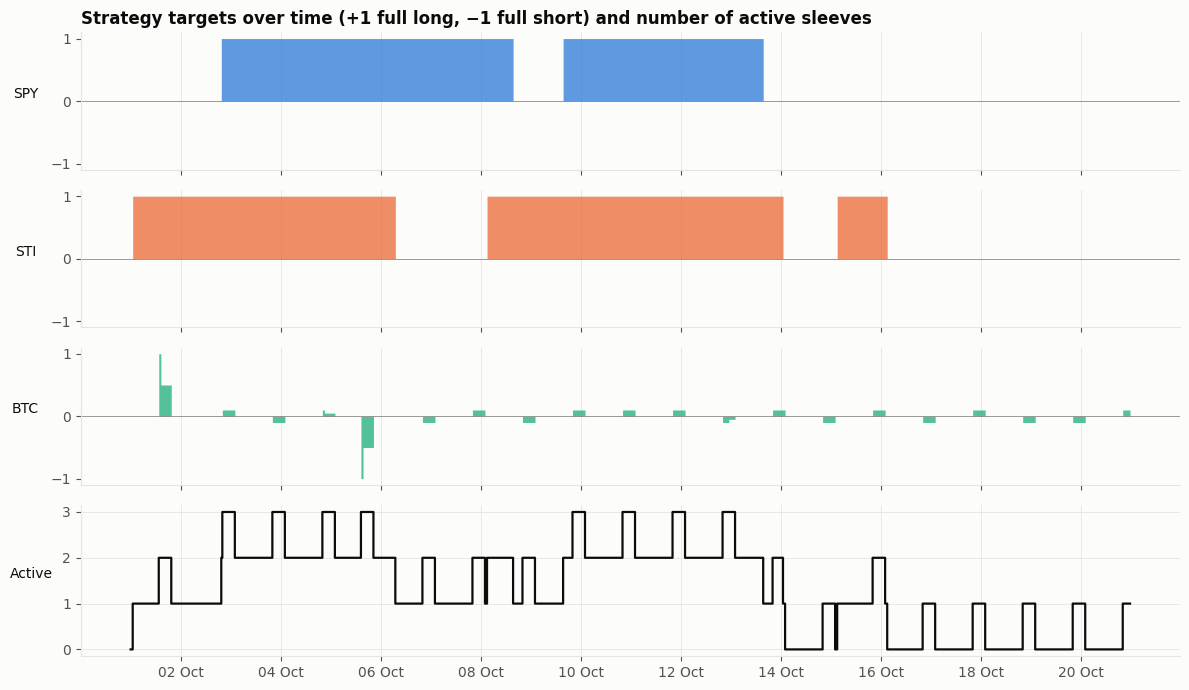

Share of time by number of active sleeves: 0: 23%, 1: 30%, 2: 37%, 3: 10%


In [14]:
sig = decisions.pivot_table(index="timestamp", columns="instrument_id", values="signal", aggfunc="last").reindex(idx).ffill().fillna(0)
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1, 1, 1.1]})
for ax, a in zip(axes, ASSETS):
    ax.fill_between(sig.index, 0, sig[a], step="post", color=COLOR[a], alpha=0.75, lw=0)
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.set_ylim(-1.1, 1.1)
    ax.set_ylabel(SHORT[a], rotation=0, labelpad=18, color=INK)
    ax.grid(axis="y", visible=False)
active = (sig.abs() > 0).sum(axis=1)
axes[3].step(active.index, active, where="post", color=INK)
axes[3].set_ylabel("Active", rotation=0, labelpad=22, color=INK)
axes[3].set_yticks([0, 1, 2, 3])
axes[0].set_title("Strategy targets over time (+1 full long, −1 full short) and number of active sleeves")
date_axis(axes[-1])
fig.tight_layout(); save(fig, "04e_signal_timeline"); plt.show()
share_active = active.value_counts(normalize=True).sort_index()
print("Share of time by number of active sleeves:", ", ".join(f"{int(k)}: {v:.0%}" for k, v in share_active.items()))

## 5. Position sizing
Sleeve budgets on 1 October are proportional to the inverse of each strategy's 60-day after-cost
return volatility (5% floor), scaled to 95% gross exposure and capped at 10% for STI and 75% for SPY
and BTC.

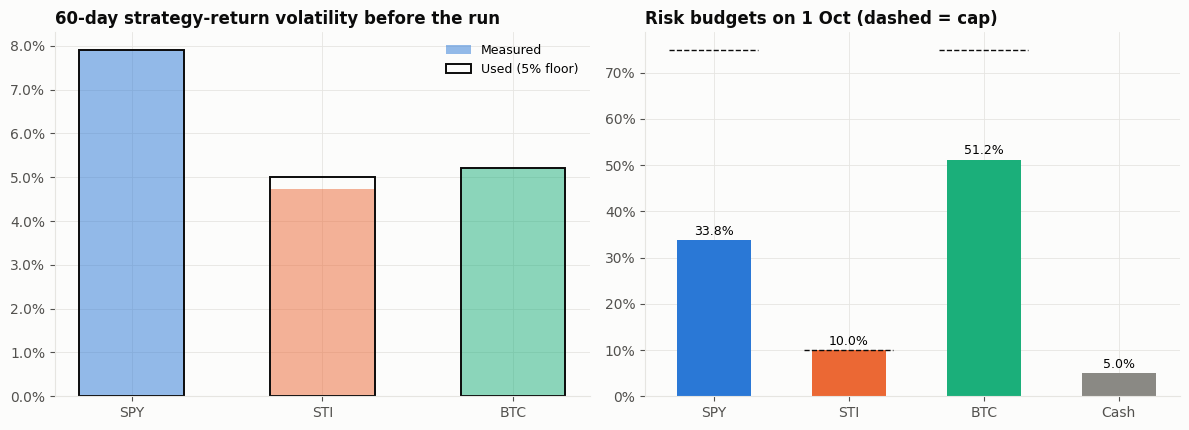

**Sleeve capital:** SPY $168,887, STI $50,000, BTC $256,113, strategic cash $25,000.

In [15]:
vd = vol_diag.set_index("instrument_id").reindex(ASSETS)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(3)
ax.bar(x, vd["annualized_volatility"], width=0.55, color=[COLOR[a] for a in ASSETS], alpha=0.5, label="Measured")
ax.bar(x, vd["effective_volatility"], width=0.55, fill=False, edgecolor=INK, lw=1.4, label="Used (5% floor)")
ax.set_xticks(x, [SHORT[a] for a in ASSETS]); ax.yaxis.set_major_formatter(PCT(1))
ax.set_title("60-day strategy-return volatility before the run")
ax.legend()
wts = [sleeve_w[a] for a in ASSETS] + [1 - sum(sleeve_w.values())]
caps = [0.75, 0.10, 0.75]
ax2.bar(range(4), wts, color=[COLOR[a] for a in ASSETS] + [MUTED], width=0.55)
for i, c in enumerate(caps):
    ax2.plot([i - 0.33, i + 0.33], [c, c], color=INK, ls="--", lw=1)
for i, v in enumerate(wts):
    ax2.annotate(f"{v:.1%}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax2.set_xticks(range(4), [SHORT[a] for a in ASSETS] + ["Cash"]); ax2.yaxis.set_major_formatter(PCT(0))
ax2.set_title("Risk budgets on 1 Oct (dashed = cap)")
fig.tight_layout(); save(fig, "05a_sizing"); plt.show()
display(Markdown(f"**Sleeve capital:** " + ", ".join(f"{SHORT[a]} {money(sleeve_cap[a])}" for a in ASSETS)
                 + f", strategic cash {money(INITIAL * wts[-1])}."))

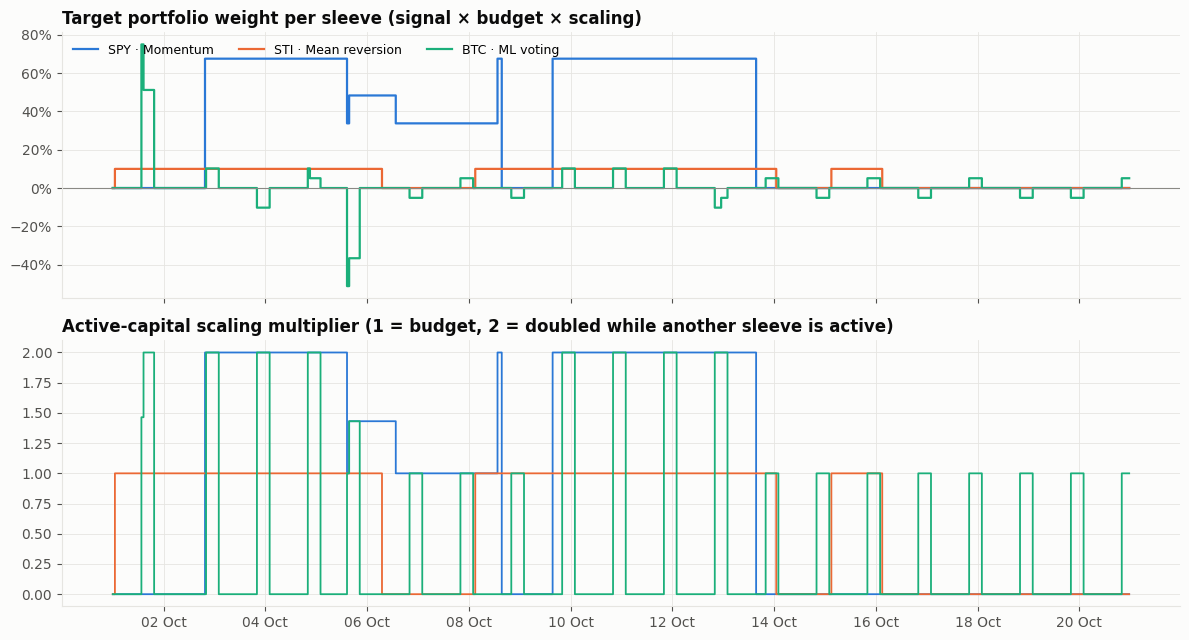

In [16]:
mult = decisions.pivot_table(index="timestamp", columns="instrument_id", values="target_scaling_multiplier", aggfunc="last").reindex(idx).ffill().fillna(0)
tw = decisions.pivot_table(index="timestamp", columns="instrument_id", values="target_weight", aggfunc="last").reindex(idx).ffill().fillna(0)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for a in ASSETS:
    ax.step(tw.index, tw[a], where="post", color=COLOR[a], label=LABEL[a])
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(PCT(0))
ax.set_title("Target portfolio weight per sleeve (signal × budget × scaling)")
ax.legend(ncol=3, loc="upper left")
for a in ASSETS:
    ax2.step(mult.index, mult[a], where="post", color=COLOR[a], lw=1.3)
ax2.set_title("Active-capital scaling multiplier (1 = budget, 2 = doubled while another sleeve is active)")
date_axis(ax2)
fig.tight_layout(); save(fig, "05b_target_weights"); plt.show()

## 6. Portfolio performance

### 6.1 Scorecard
Portfolio, benchmark and sleeve metrics computed with `src/metrics.compute_metrics`. Sleeve returns
are measured on sleeve capital. Annualised ratios extrapolate a 20-day window and are descriptive
of this period rather than estimates of long-run performance.

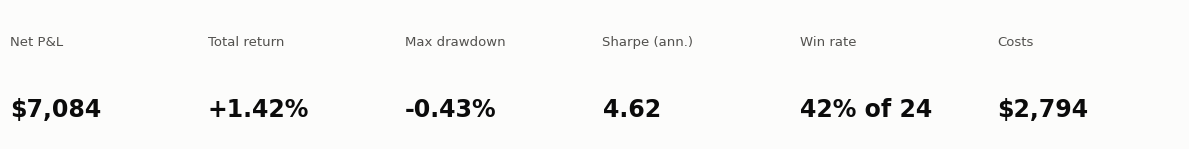

,Total Return,Annual Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Max Drawdown,Calmar Ratio,Net P&L (USD)
Portfolio,+1.42%,+29.27%,4.68%,4.62,15.60,-0.43%,67.5,"7,084"
Portfolio before costs,+1.98%,+42.91%,5.33%,5.95,25.26,-0.38%,111.7,"9,878"
"Same weights, buy & hold",-0.66%,-11.42%,15.35%,-0.99,-1.23,-5.04%,-2.3,"-3,311"
Equal-weight buy & hold,-1.71%,-27.04%,13.42%,-2.59,-2.93,-5.07%,-5.3,"-8,562"
SPY buy & hold,+0.61%,+11.73%,9.42%,0.78,1.05,-2.50%,4.7,"3,048"
STI buy & hold,-5.03%,-61.05%,18.53%,-5.21,-5.38,-6.59%,-9.3,"-25,174"
BTC buy & hold,-0.71%,-12.23%,25.88%,-0.54,-0.72,-7.75%,-1.6,"-3,560"
SPY sleeve,+1.17%,+23.59%,6.89%,2.50,5.94,-1.11%,21.2,"1,972"
STI sleeve,+0.83%,+16.24%,8.43%,1.33,2.20,-2.10%,7.7,414
BTC sleeve,+1.83%,+39.35%,6.45%,4.54,27.97,-0.87%,45.1,"4,699"


In [17]:
def metrics_for(eq):
    m = M.compute_metrics(eq, periods_per_year=365, risk_free_rate=RF_SERIES, metric_frequency="daily",
                          drop_incomplete_final_day=True, annualize_by_elapsed_time=True)
    m["Sortino Ratio"] = M.sortino_ratio(eq, periods_per_year=365, risk_free_rate=RF_SERIES,
                                       metric_frequency="daily", drop_incomplete_final_day=True)
    m["Calmar Ratio"] = M.calmar_ratio(eq, periods_per_year=365, annualize_by_elapsed_time=True)
    return m[["Total Return", "Annual Return", "Annual Volatility", "Sharpe Ratio", "Sortino Ratio",
              "Max Drawdown", "Calmar Ratio"]].astype(float)


table = pd.DataFrame({k: metrics_for(v) for k, v in series.items()}).T
table["Net P&L (USD)"] = [series[k].iloc[-1] - series[k].iloc[0] for k in table.index]
tiles = [("Net P&L", money(summary["Net Profit"])), ("Total return", f"{summary['Total Return']:+.2%}"),
         ("Max drawdown", f"{summary['Max Drawdown']:.2%}"), ("Sharpe (ann.)", f"{summary['Sharpe Ratio']:.2f}"),
         ("Win rate", f"{summary['Win Rate']:.0%} of {int(summary['Number of Trades'])}"),
         ("Costs", money(summary["Total Transaction Cost"]))]
fig, axes = plt.subplots(1, 6, figsize=(12, 1.6))
for ax, (k, v) in zip(axes, tiles):
    ax.axis("off")
    ax.text(0, 0.72, k, fontsize=9.5, color=INK2, transform=ax.transAxes)
    ax.text(0, 0.18, v, fontsize=17, weight="bold", color=INK, transform=ax.transAxes)
fig.tight_layout(); save(fig, "06a_tiles"); plt.show()
fmt = {c: "{:+.2%}" for c in ["Total Return", "Annual Return", "Max Drawdown"]}
fmt.update({"Annual Volatility": "{:.2%}", "Sharpe Ratio": "{:.2f}", "Sortino Ratio": "{:.2f}",
            "Calmar Ratio": "{:.1f}", "Net P&L (USD)": "{:,.0f}"})
display(table.style.format(fmt, na_rep="–").set_caption("Portfolio, benchmarks and sleeves (sleeve returns are on sleeve capital)"))

In [18]:
def drawdown_profile(eq: pd.Series) -> dict:
    out = {}
    for depth, label in ((0.001, "≥ 0.1%"), (0.0025, "≥ 0.25%"), (0.01, "≥ 1%")):
        out[f"Drawdowns {label}"] = len(M.drawdown_episodes(eq, depth))
    eps = M.drawdown_episodes(eq, 0.001)
    out["Longest drawdown (days)"] = eps["duration"].max().total_seconds() / 86400 if len(eps) else 0.0
    return out


def trade_stats(t: pd.DataFrame) -> dict:
    return {"Number of trades": len(t),
            "Win rate": (t["net_pnl"] > 0).mean() if len(t) else np.nan,
            "Average holding period (hours)": t["holding_hours"].mean() if len(t) else np.nan,
            "Profit per trade (USD)": t["net_pnl"].mean() if len(t) else np.nan}


cols = {}
for name, key, t in [("Portfolio", "Portfolio", trades)] + \
        [(LABEL[a], f"{SHORT[a]} sleeve", trades[trades["asset"].eq(a)]) for a in ASSETS]:
    row = {"Annual return": table.at[key, "Annual Return"],
           "Sharpe ratio": table.at[key, "Sharpe Ratio"],
           "Max drawdown": table.at[key, "Max Drawdown"],
           "Annual volatility": table.at[key, "Annual Volatility"]}
    row.update(trade_stats(t))
    row.update(drawdown_profile(series[key]))
    cols[name] = row
metric_summary = pd.DataFrame(cols)

fmt_rows = {"Annual return": "{:+.2%}", "Max drawdown": "{:.2%}", "Annual volatility": "{:.2%}",
            "Win rate": "{:.1%}", "Sharpe ratio": "{:.2f}", "Average holding period (hours)": "{:.1f}",
            "Profit per trade (USD)": "${:,.2f}", "Longest drawdown (days)": "{:.1f}"}
shown = metric_summary.copy().astype(object)
for r in shown.index:
    for c in shown.columns:
        v = metric_summary.at[r, c]
        shown.at[r, c] = fmt_rows.get(r, "{:,.0f}").format(v) if pd.notna(v) else "–"
display(shown.style.set_caption("Performance metric summary — test period 1–20 Oct 2026 (sleeve returns on sleeve capital)"))
metric_summary.to_csv(FIG_DIR / "performance_metric_summary.csv")

,Portfolio,SPY · Momentum,STI · Mean reversion,BTC · ML voting
Annual return,+29.27%,+23.59%,+16.24%,+39.35%
Sharpe ratio,4.62,2.50,1.33,4.54
Max drawdown,-0.43%,-1.11%,-2.10%,-0.87%
Annual volatility,4.68%,6.89%,8.43%,6.45%
Number of trades,24,2,3,19
Win rate,41.7%,50.0%,33.3%,42.1%
Average holding period (hours),26.8,118.0,97.3,6.0
Profit per trade (USD),$290.74,$985.76,$137.96,$241.70
Drawdowns ≥ 0.1%,3,3,3,4
Drawdowns ≥ 0.25%,3,1,1,2


In [19]:
eps = M.drawdown_episodes(series["Portfolio"], 0.001).copy()
eps["depth"] = eps["depth"].map("{:.2%}".format)
eps["duration (days)"] = (eps["duration"].dt.total_seconds() / 86400).round(2)
for c in ("start", "trough", "end"):
    eps[c] = pd.to_datetime(eps[c]).dt.strftime("%d %b %H:%M").where(eps[c].notna(), "not recovered")
display(eps[["start", "trough", "end", "depth", "duration (days)", "recovered"]]
        .style.set_caption("Portfolio drawdown episodes deeper than 0.1% (intraday equity)"))

,start,trough,end,depth,duration (days),recovered
0,01 Oct 17:30,02 Oct 07:00,05 Oct 14:00,-0.35%,3.850000,True
1,05 Oct 16:30,06 Oct 02:00,06 Oct 13:30,-0.26%,0.880000,True
2,06 Oct 15:30,19 Oct 22:00,not recovered,-0.43%,14.330000,False


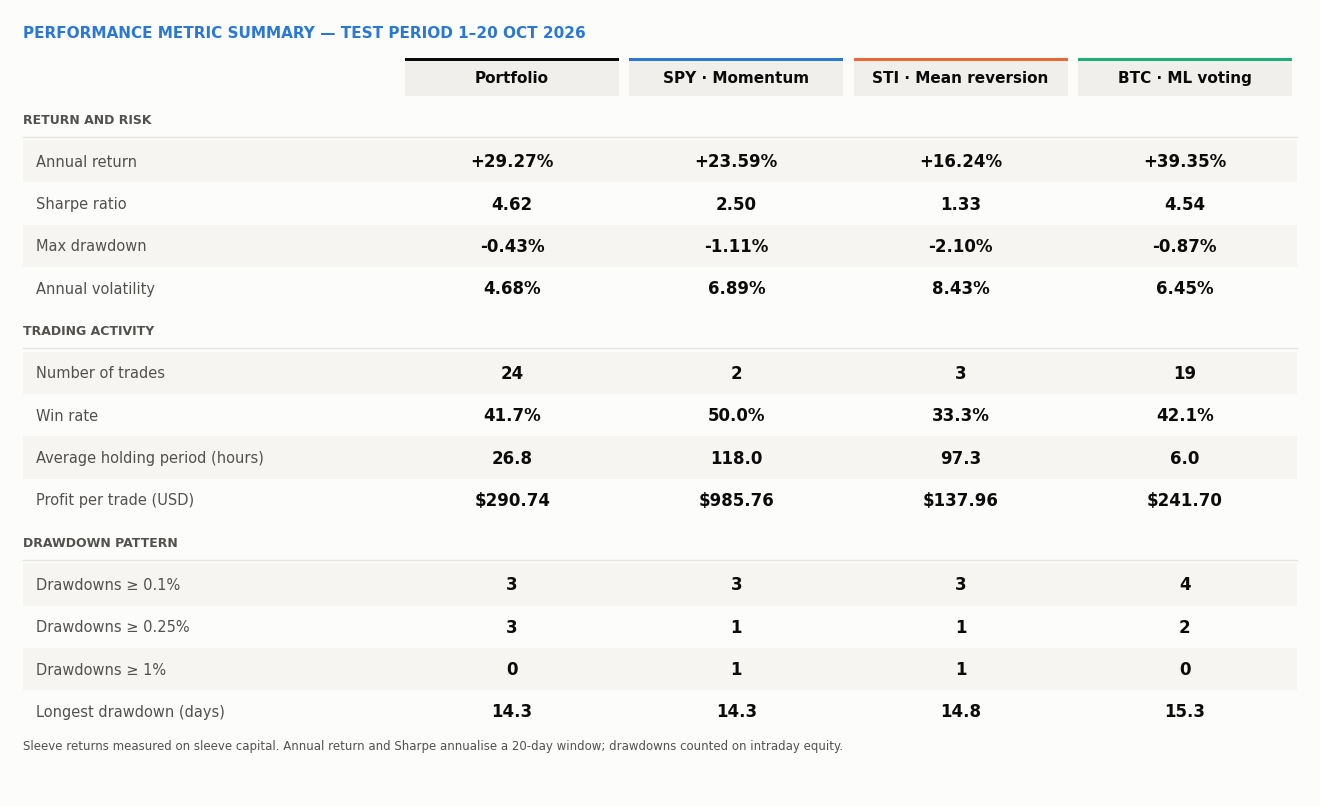

In [20]:
def draw_metric_grid(cells: pd.DataFrame, title: str, sections: list, col_colors: dict,
                     note: str | None = None, fname: str | None = None):
    """Render a metrics table (rows = metrics, columns = portfolio/sleeves, values = formatted strings)
    as a card-style grid matching the key-metrics tiles."""
    cols = list(cells.columns)
    n_lines = 1 + sum(1 + len(rows) for _, rows in sections)
    row_h, label_w = 0.42, 0.30
    col_w = (1 - label_w - 0.01) / len(cols)
    fig = plt.figure(figsize=(13, row_h * n_lines + (1.15 if note else 0.85)))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, 1); ax.set_ylim(0, n_lines + (2.6 if note else 1.9)); ax.axis("off")
    top = n_lines + (2.6 if note else 1.9)
    ax.text(0.01, top - 0.55, title.upper(), fontsize=11, weight="bold", color=POS, va="center")
    y = top - 1.6
    for j, c in enumerate(cols):                                    # column headers
        x0 = label_w + j * col_w
        ax.add_patch(plt.Rectangle((x0 + 0.004, y - 0.45), col_w - 0.008, 0.9, color=MID, lw=0))
        ax.add_patch(plt.Rectangle((x0 + 0.004, y + 0.36), col_w - 0.008, 0.09, color=col_colors.get(c, INK), lw=0))
        ax.text(x0 + col_w / 2, y - 0.02, c, ha="center", va="center", fontsize=11, weight="bold", color=INK)
    y -= 1.0
    band = 0
    for sec_name, rows in sections:
        ax.text(0.01, y, sec_name.upper(), fontsize=9, weight="bold", color=INK2, va="center")
        ax.plot([0.01, 0.99], [y - 0.42, y - 0.42], color=GRID, lw=1)
        y -= 1.0
        for r in rows:
            if band % 2 == 0:
                ax.add_patch(plt.Rectangle((0.01, y - 0.5), 0.98, 1.0, color="#f6f5f1", lw=0))
            ax.text(0.02, y, r, fontsize=10.5, color=INK2, va="center")
            for j, c in enumerate(cols):
                ax.text(label_w + j * col_w + col_w / 2, y, cells.at[r, c], ha="center", va="center",
                        fontsize=12, weight="bold", color=INK)
            y -= 1.0
            band += 1
    if note:
        ax.text(0.01, y + 0.2, note, fontsize=8.5, color=INK2, va="center")
    if fname:
        save(fig, fname)
    plt.show()


GRID_COLORS = {"Portfolio": INK, **{LABEL[a]: COLOR[a] for a in ASSETS}}

draw_metric_grid(
    shown,
    "Performance metric summary — test period 1–20 Oct 2026",
    [("Return and risk", ["Annual return", "Sharpe ratio", "Max drawdown", "Annual volatility"]),
     ("Trading activity", ["Number of trades", "Win rate", "Average holding period (hours)", "Profit per trade (USD)"]),
     ("Drawdown pattern", ["Drawdowns ≥ 0.1%", "Drawdowns ≥ 0.25%", "Drawdowns ≥ 1%", "Longest drawdown (days)"])],
    GRID_COLORS,
    note="Sleeve returns measured on sleeve capital. Annual return and Sharpe annualise a 20-day window; drawdowns counted on intraday equity.",
    fname="06a_performance_metric_summary_grid",
)

### 6.2 Equity curve against benchmarks
Two frictionless benchmarks: the 1 October sleeve budgets held without trading (*same weights,
buy & hold*), and an equal-weight buy-and-hold of the three assets. The dotted line adds back
transaction costs.

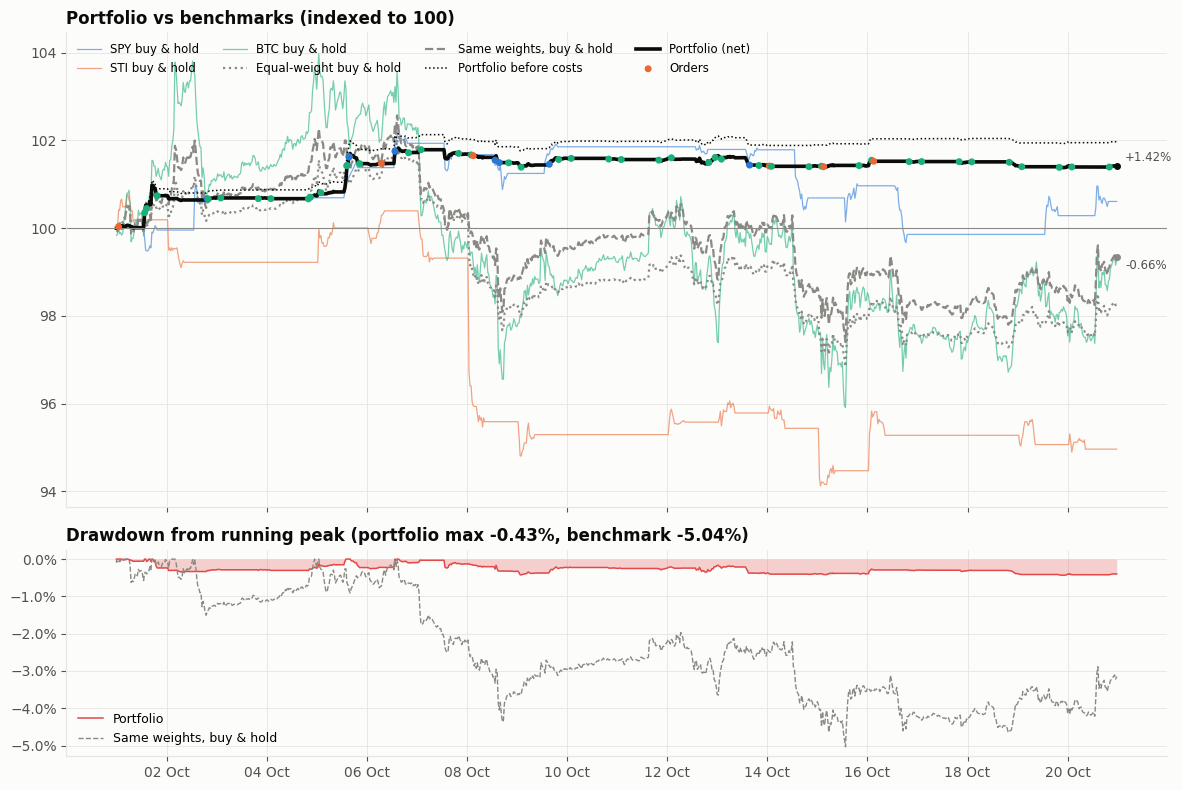

In [21]:
base = lambda s: 100 * s / s.iloc[0]  # noqa: E731
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
for a in ASSETS:
    s = base(series[f"{SHORT[a]} buy & hold"]).iloc[1:]
    ax.plot(s.index, s, color=COLOR[a], lw=0.9, alpha=0.6, label=f"{SHORT[a]} buy & hold")
for name, style in (("Equal-weight buy & hold", dict(color=MUTED, ls=":")),
                    ("Same weights, buy & hold", dict(color=MUTED, ls="--")),
                    ("Portfolio before costs", dict(color=INK, ls=":", lw=1.1))):
    s = base(series[name]).iloc[1:]
    ax.plot(s.index, s, label=name, **style)
s = base(series["Portfolio"]).iloc[1:]
ax.plot(s.index, s, color=INK, lw=2.6, label="Portfolio (net)")
for name, c, dy in (("Portfolio", INK, 6), ("Same weights, buy & hold", MUTED, -6)):
    v = base(series[name]).iloc[-1]
    end_label(ax, idx[-1], v, f"{v - 100:+.2f}%", c, dy)
f_ = fills.copy()
f_["eq"] = 100 * equity.reindex(f_["timestamp"]).values / INITIAL
ax.scatter(f_["timestamp"], f_["eq"], s=16, color=[COLOR[a] for a in f_["asset"]], zorder=7, label="Orders")
ax.axhline(100, color=MUTED, lw=0.8)
ax.set_title("Portfolio vs benchmarks (indexed to 100)")
ax.legend(ncol=4, loc="upper left", fontsize=8.5)
dd = M.drawdown_series(series["Portfolio"])
ax2.fill_between(dd.index, dd, 0, color=NEG, alpha=0.25, lw=0)
ax2.plot(dd.index, dd, color=NEG, lw=1.1, label="Portfolio")
dd_b = M.drawdown_series(series["Same weights, buy & hold"])
ax2.plot(dd_b.index, dd_b, color=MUTED, lw=1, ls="--", label="Same weights, buy & hold")
ax2.yaxis.set_major_formatter(PCT(1))
ax2.set_title(f"Drawdown from running peak (portfolio max {dd.min():.2%}, benchmark {dd_b.min():.2%})")
ax2.legend(loc="lower left")
date_axis(ax2)
fig.tight_layout(); save(fig, "06b_equity_vs_benchmarks"); plt.show()

### 6.3 Return distribution

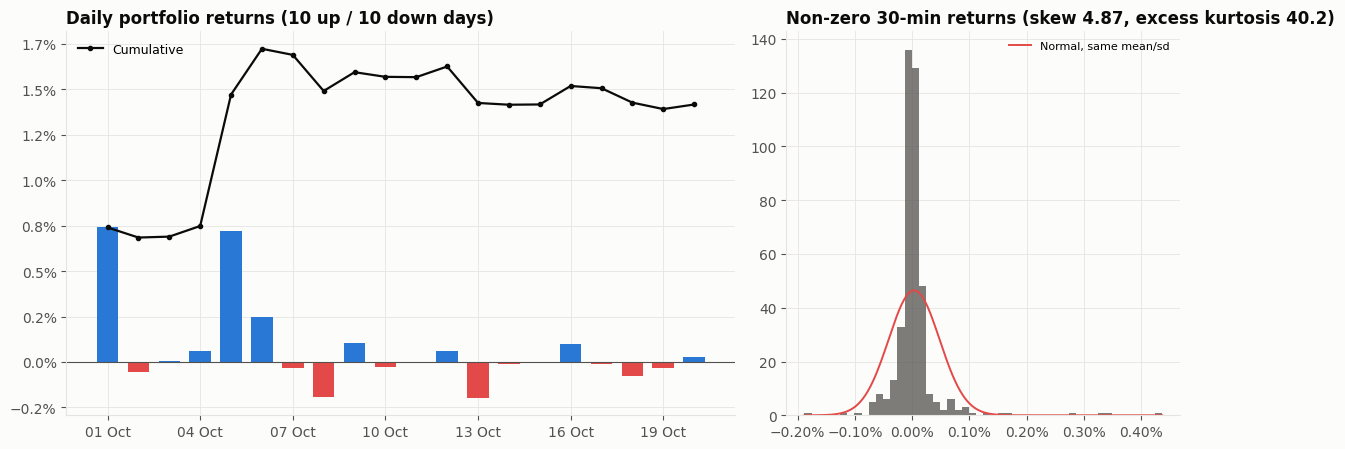

Best day 2026-10-01 +0.74% | worst day 2026-10-13 -0.20%


In [22]:
daily_lv = with_start(equity, INITIAL).copy()
daily_lv.index = daily_lv.index.tz_convert("UTC")
dlv = daily_lv.iloc[1:].resample("1D").last()
dret = pd.concat([pd.Series([INITIAL], index=[dlv.index[0] - pd.Timedelta(days=1)]), dlv]).pct_change().dropna()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.7, 1]})
ax.bar(dret.index, dret, color=np.where(dret >= 0, POS, NEG), width=0.7)
ax.plot(dret.index, (1 + dret).cumprod() - 1, color=INK, marker="o", ms=3, label="Cumulative")
ax.yaxis.set_major_formatter(PCT(1)); ax.axhline(0, color=INK2, lw=0.8)
ax.set_title(f"Daily portfolio returns ({(dret > 0).sum()} up / {(dret < 0).sum()} down days)")
ax.legend(loc="upper left"); date_axis(ax, 3)
nz = r30[r30 != 0]
counts, edges, _ = ax2.hist(nz, bins=50, color=INK2, alpha=0.75)
xs = np.linspace(edges[0], edges[-1], 300)
pdf = np.exp(-0.5 * ((xs - nz.mean()) / nz.std()) ** 2) / (nz.std() * np.sqrt(2 * np.pi))
ax2.plot(xs, pdf * len(nz) * (edges[1] - edges[0]), color=NEG, lw=1.4, label="Normal, same mean/sd")
ax2.xaxis.set_major_formatter(PCT(2))
ax2.set_title(f"Non-zero 30-min returns (skew {nz.skew():.2f}, excess kurtosis {nz.kurt():.1f})")
ax2.legend(fontsize=8)
fig.tight_layout(); save(fig, "06c_daily_returns_distribution"); plt.show()
print(f"Best day {dret.idxmax().date()} {dret.max():+.2%} | worst day {dret.idxmin().date()} {dret.min():+.2%}")

### 6.4 Rolling risk and the reliability of performance ratios
The window provides 960 thirty-minute observations for measuring risk but only 20 daily returns for
estimating mean return. Rolling volatility, correlation and exposure are therefore well measured,
whereas return-based ratios such as the Sharpe ratio carry wide sampling error and are reported
with confidence bands.

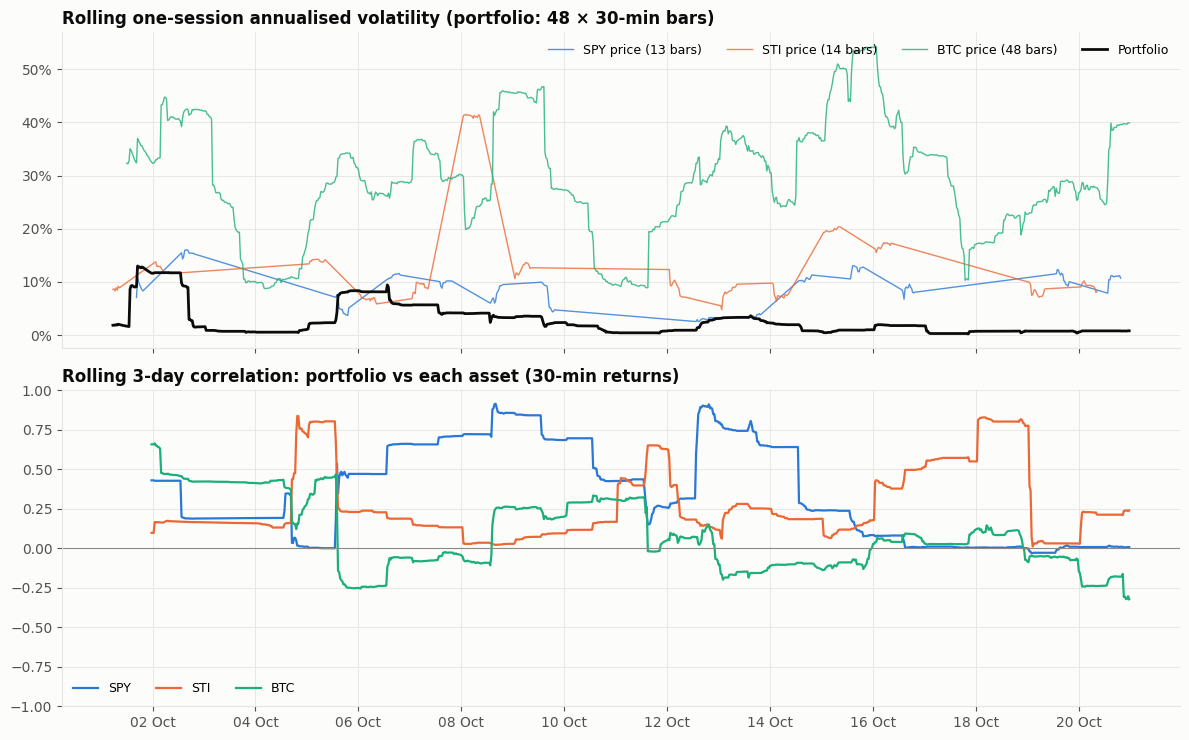

Portfolio 30-min vol annualised over the window: 3.9%; daily-return vol: 4.7%


In [23]:
ann = np.sqrt(48 * 365)
asset_r = close_usd[ASSETS].pct_change()
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
ax = axes[0]
for a in ASSETS:   # each asset on its own bars: one session's worth of bars, annualised by its own calendar
    own = decisions[decisions["instrument_id"].eq(a)].set_index("timestamp")["close_usd"].pct_change()
    per_day = int(round(own.groupby(own.index.date).size().median()))
    days = 365 if a == "btc_usdt" else 252
    ax.plot(own.index, own.rolling(per_day, min_periods=max(4, per_day // 2)).std() * np.sqrt(per_day * days),
            color=COLOR[a], lw=1, alpha=0.8, label=f"{SHORT[a]} price ({per_day} bars)")
ax.plot(idx, r30.rolling(48, min_periods=12).std() * ann, color=INK, lw=2, label="Portfolio")
ax.yaxis.set_major_formatter(PCT(0)); ax.set_title("Rolling one-session annualised volatility (portfolio: 48 × 30-min bars)")
ax.legend(ncol=4, loc="upper right")
ax = axes[1]
for a in ASSETS:
    ax.plot(idx, r30.rolling(144, min_periods=48).corr(asset_r[a].fillna(0)), color=COLOR[a], label=SHORT[a])
ax.axhline(0, color=MUTED, lw=0.8); ax.set_ylim(-1, 1)
ax.set_title("Rolling 3-day correlation: portfolio vs each asset (30-min returns)")
ax.legend(ncol=3, loc="lower left")
date_axis(axes[-1])
fig.tight_layout(); save(fig, "06d_rolling"); plt.show()
vol_full = r30.std() * ann
print(f"Portfolio 30-min vol annualised over the window: {vol_full:.1%}; daily-return vol: {table.loc['Portfolio', 'Annual Volatility']:.1%}")

**Sharpe ratio to date.** Recomputed after each UTC day with a 95% confidence band of ±1.96
standard errors (Lo, 2002: SE ≈ √((1 + ½·SR²)/n) per day, annualised), complemented by a bootstrap
of daily excess returns.

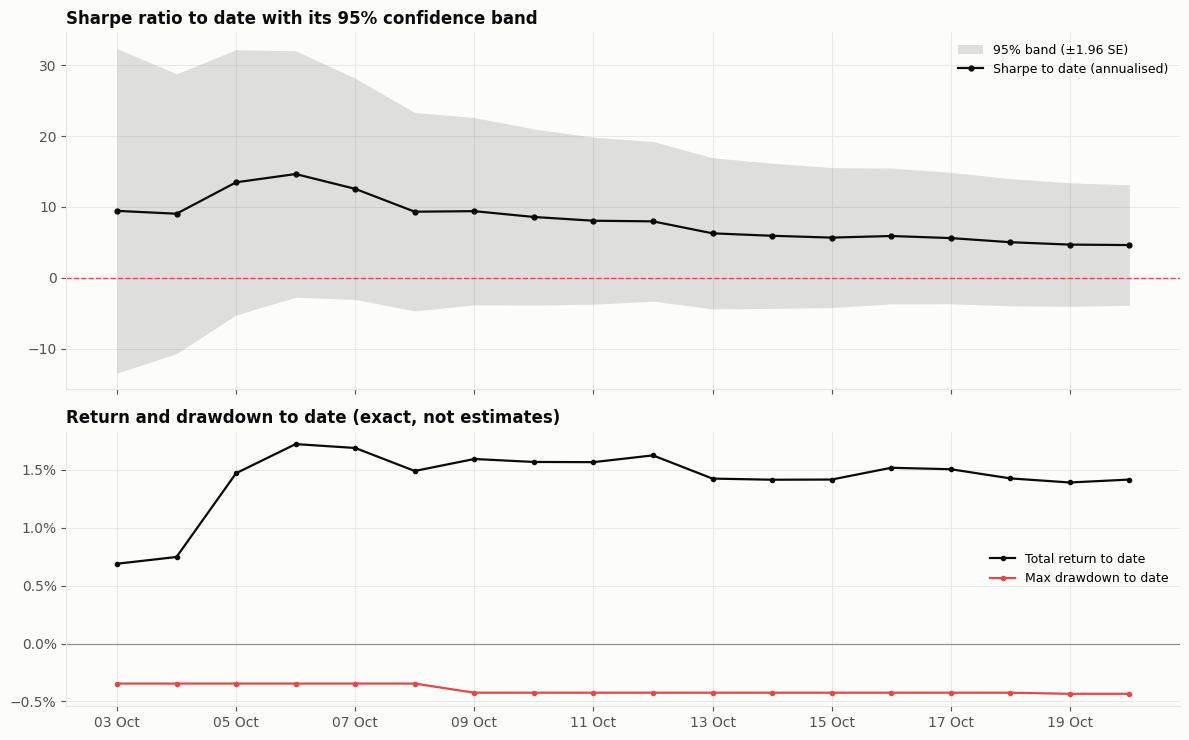

**Final Sharpe 4.62**, 95% band **[-3.9, 13.1]** (normal approx.); bootstrap 5th–95th percentile **[-3.8, 9.5]**. Probability the true Sharpe is above zero: **86%** (normal) / **87%** (bootstrap). The evidence of a positive risk-adjusted return is meaningful but not statistically conclusive over this window.

,n days,Sharpe,lo,hi,P(true Sharpe > 0),Total return,Max drawdown
date,,,,,,,
2026-10-03 00:00:00+00:00,3,9.44,-13.5,32.3,79%,+0.69%,-0.35%
2026-10-04 00:00:00+00:00,4,9.04,-10.7,28.8,82%,+0.75%,-0.35%
2026-10-05 00:00:00+00:00,5,13.47,-5.2,32.2,92%,+1.47%,-0.35%
2026-10-06 00:00:00+00:00,6,14.64,-2.7,32.0,95%,+1.72%,-0.35%
2026-10-07 00:00:00+00:00,7,12.55,-3.1,28.2,94%,+1.69%,-0.35%
2026-10-08 00:00:00+00:00,8,9.32,-4.7,23.3,90%,+1.49%,-0.35%
2026-10-09 00:00:00+00:00,9,9.40,-3.8,22.6,92%,+1.59%,-0.42%
2026-10-10 00:00:00+00:00,10,8.58,-3.8,21.0,91%,+1.57%,-0.42%
2026-10-11 00:00:00+00:00,11,8.05,-3.7,19.8,91%,+1.57%,-0.42%


In [24]:
dr_all = M.daily_portfolio_returns(series["Portfolio"])
rf_d = (1 + RF_SERIES.reindex(RF_SERIES.index.union(dr_all.index)).ffill().reindex(dr_all.index)) ** (1 / 365) - 1
excess = dr_all - rf_d
rows = []
for n in range(3, len(excess) + 1):
    e = excess.iloc[:n]
    sr_d = e.mean() / e.std(ddof=1)
    se_d = math.sqrt((1 + 0.5 * sr_d ** 2) / n)
    eq_d = series["Portfolio"].loc[:e.index[-1] + pd.Timedelta(days=1) - pd.Timedelta(minutes=1)]
    rows.append({"date": e.index[-1], "n days": n, "Sharpe": sr_d * math.sqrt(365),
                 "lo": (sr_d - 1.96 * se_d) * math.sqrt(365), "hi": (sr_d + 1.96 * se_d) * math.sqrt(365),
                 "P(true Sharpe > 0)": 0.5 * (1 + math.erf(sr_d / se_d / math.sqrt(2))),
                 "Total return": eq_d.iloc[-1] / INITIAL - 1, "Max drawdown": M.max_drawdown(eq_d)})
exp = pd.DataFrame(rows).set_index("date")

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax.fill_between(exp.index, exp["lo"], exp["hi"], color=INK, alpha=0.12, lw=0, label="95% band (±1.96 SE)")
ax.plot(exp.index, exp["Sharpe"], color=INK, marker="o", ms=3.5, label="Sharpe to date (annualised)")
ax.axhline(0, color=NEG, lw=1, ls="--")
ax.set_title("Sharpe ratio to date with its 95% confidence band")
ax.legend(loc="upper right")
ax2.plot(exp.index, exp["Total return"], color=INK, marker="o", ms=3, label="Total return to date")
ax2.plot(exp.index, exp["Max drawdown"], color=NEG, marker="o", ms=3, label="Max drawdown to date")
ax2.yaxis.set_major_formatter(PCT(1)); ax2.axhline(0, color=MUTED, lw=0.8)
ax2.set_title("Return and drawdown to date (exact, not estimates)"); ax2.legend(loc="center right")
date_axis(ax2)
fig.tight_layout(); save(fig, "06d2_sharpe_band"); plt.show()

rng = np.random.default_rng(7)
ex_np = excess.to_numpy()
boot = np.array([(lambda x: x.mean() / x.std(ddof=1) * math.sqrt(365))(rng.choice(ex_np, len(ex_np), replace=True))
                 for _ in range(20000)])
last = exp.iloc[-1]
display(Markdown(
    f"**Final Sharpe {last['Sharpe']:.2f}**, 95% band **[{last['lo']:.1f}, {last['hi']:.1f}]** (normal approx.); "
    f"bootstrap 5th–95th percentile **[{np.percentile(boot, 5):.1f}, {np.percentile(boot, 95):.1f}]**. "
    f"Probability the true Sharpe is above zero: **{last['P(true Sharpe > 0)']:.0%}** (normal) / "
    f"**{(boot > 0).mean():.0%}** (bootstrap). The evidence of a positive risk-adjusted return is "
    f"meaningful but not statistically conclusive over this window."))
display(exp[["n days", "Sharpe", "lo", "hi", "P(true Sharpe > 0)", "Total return", "Max drawdown"]].style.format(
    {"Sharpe": "{:.2f}", "lo": "{:.1f}", "hi": "{:.1f}", "P(true Sharpe > 0)": "{:.0%}",
     "Total return": "{:+.2%}", "Max drawdown": "{:.2%}"}).set_caption("Metrics to date"))

**Return concentration.** Daily returns sorted from best to worst with their running total, and the
window return after excluding the best days.

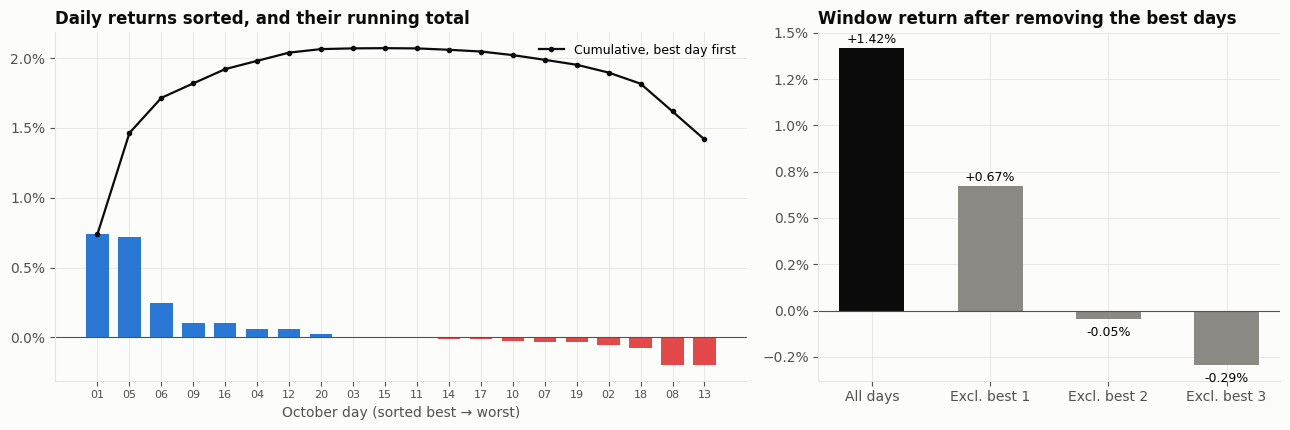

Best two days: 01 Oct +0.74%, 05 Oct +0.72% | window return without them: -0.05%


In [25]:
srt = dr_all.sort_values(ascending=False)
cum = (1 + srt).cumprod() - 1
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax.bar(range(len(srt)), srt.values, color=np.where(srt.values >= 0, POS, NEG), width=0.7)
ax.plot(range(len(srt)), cum.values, color=INK, marker="o", ms=3, label="Cumulative, best day first")
ax.set_xticks(range(len(srt)), [d.strftime("%d") for d in srt.index], fontsize=8)
ax.set_xlabel("October day (sorted best → worst)"); ax.yaxis.set_major_formatter(PCT(1))
ax.axhline(0, color=INK2, lw=0.8); ax.legend(loc="upper right")
ax.set_title("Daily returns sorted, and their running total")
excl = {f"Excl. best {k}": (1 + srt.iloc[k:]).prod() - 1 for k in range(0, 4)}
excl["All days"] = excl.pop("Excl. best 0")
ks = ["All days", "Excl. best 1", "Excl. best 2", "Excl. best 3"]
ax2.bar(ks, [excl[k] for k in ks], color=[INK, MUTED, MUTED, MUTED], width=0.55)
for i, k in enumerate(ks):
    ax2.annotate(f"{excl[k]:+.2%}", (i, excl[k]), xytext=(0, 4 if excl[k] >= 0 else -12), textcoords="offset points", ha="center", fontsize=9)
ax2.axhline(0, color=INK2, lw=0.8); ax2.yaxis.set_major_formatter(PCT(1))
ax2.set_title("Window return after removing the best days")
fig.tight_layout(); save(fig, "06d3_return_concentration"); plt.show()
print("Best two days:", ", ".join(f"{d:%d %b} {v:+.2%}" for d, v in srt.head(2).items()),
      f"| window return without them: {excl['Excl. best 2']:+.2%}")

### 6.5 Exposure

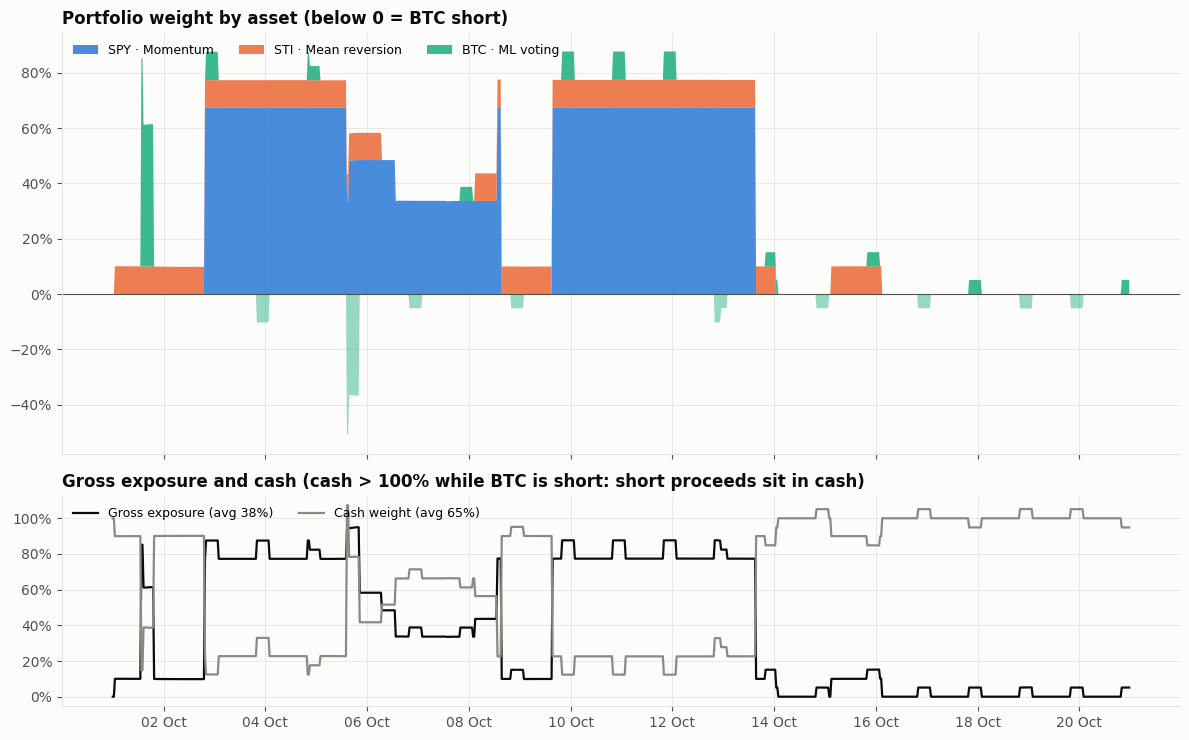

Time in market: SPY 49%, STI 61%, BTC 25% | any sleeve 77%


In [26]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
longs, shorts = weights.clip(lower=0), weights.clip(upper=0)
ax.stackplot(idx, *[longs[a] for a in ASSETS], colors=[COLOR[a] for a in ASSETS], labels=[LABEL[a] for a in ASSETS], alpha=0.85)
ax.stackplot(idx, *[shorts[a] for a in ASSETS], colors=[COLOR[a] for a in ASSETS], alpha=0.45)
ax.axhline(0, color=INK2, lw=0.8)
ax.yaxis.set_major_formatter(PCT(0))
ax.set_title("Portfolio weight by asset (below 0 = BTC short)")
ax.legend(ncol=3, loc="upper left")
cash_w = curve["cash"] / curve["equity"]
ax2.plot(idx, curve["gross_exposure"], color=INK, label=f"Gross exposure (avg {curve['gross_exposure'].mean():.0%})")
ax2.plot(idx, cash_w, color=MUTED, label=f"Cash weight (avg {cash_w.mean():.0%})")
ax2.yaxis.set_major_formatter(PCT(0))
ax2.set_title("Gross exposure and cash (cash > 100% while BTC is short: short proceeds sit in cash)")
ax2.legend(loc="upper left", ncol=2)
date_axis(ax2)
fig.tight_layout(); save(fig, "06e_exposure"); plt.show()
held = (pos != 0)
print("Time in market:", ", ".join(f"{SHORT[a]} {held[a].mean():.0%}" for a in ASSETS),
      f"| any sleeve {held.any(axis=1).mean():.0%}")

### 6.6 Timing of P&L
Portfolio P&L aggregated by UTC day and hour, and by hour of day split by sleeve.

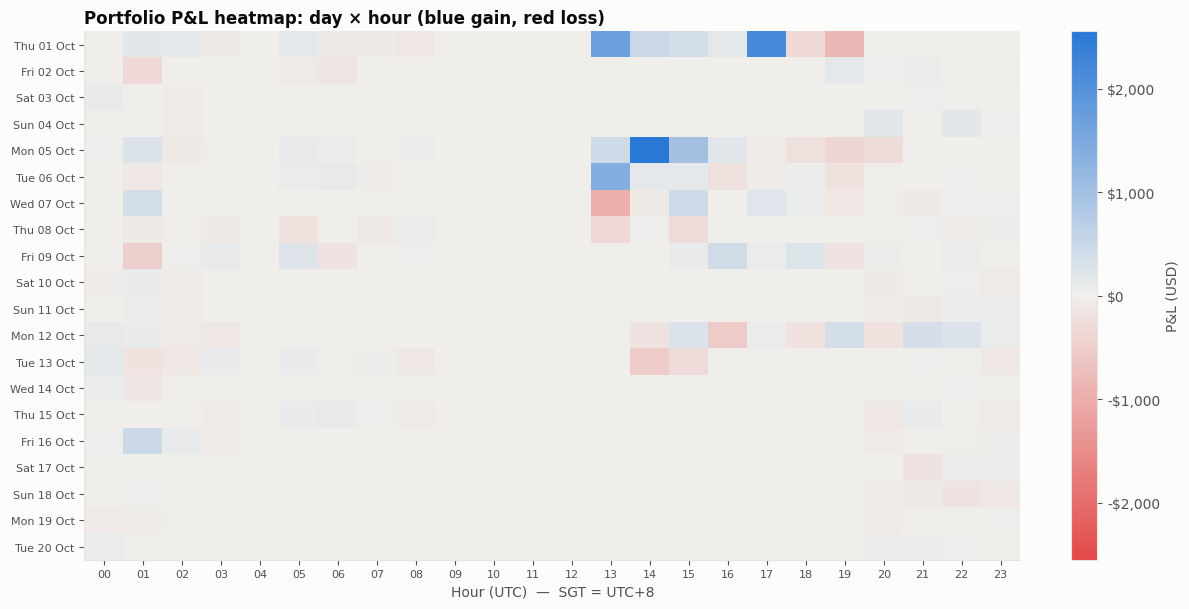

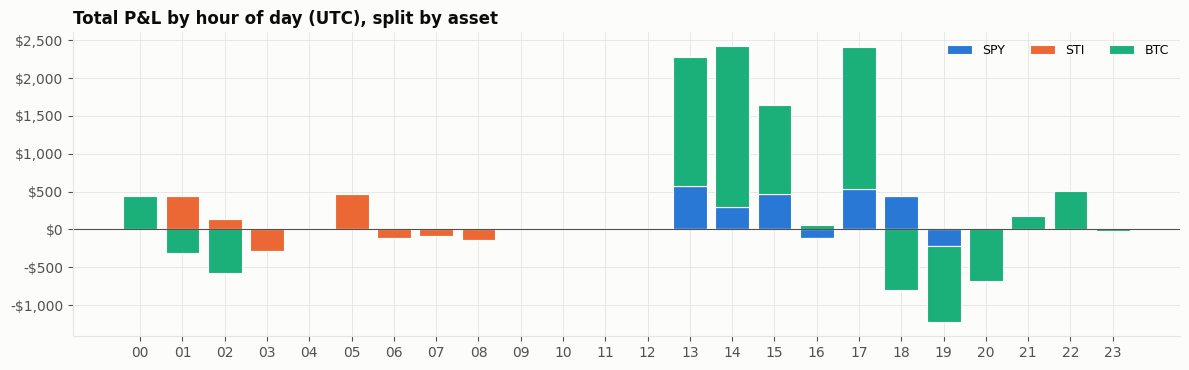

In [27]:
dpnl = pnl.diff().fillna(pnl.iloc[0])
tot = dpnl.sum(axis=1)
hm = tot.groupby([tot.index.date, tot.index.hour]).sum().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
v = np.abs(hm.values).max()
fig, ax = plt.subplots(figsize=(12, 6.2))
im = ax.imshow(hm.values, aspect="auto", cmap=DIVERGING, vmin=-v, vmax=v)
ax.grid(False)
ax.set_yticks(range(len(hm)), [pd.Timestamp(d).strftime("%a %d %b") for d in hm.index], fontsize=8)
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)], fontsize=8)
ax.set_xlabel("Hour (UTC)  —  SGT = UTC+8")
fig.colorbar(im, ax=ax, fraction=0.03, label="P&L (USD)", format=USD)
ax.set_title("Portfolio P&L heatmap: day × hour (blue gain, red loss)")
fig.tight_layout(); save(fig, "06f_pnl_heatmap"); plt.show()
by_hour = dpnl.groupby(dpnl.index.hour).sum()
fig, ax = plt.subplots(figsize=(12, 3.8))
bottom_p, bottom_n = np.zeros(24), np.zeros(24)
for a in ASSETS:
    v_ = by_hour[a].reindex(range(24), fill_value=0).values
    p_, n_ = np.clip(v_, 0, None), np.clip(v_, None, 0)
    ax.bar(range(24), p_, bottom=bottom_p, color=COLOR[a], label=SHORT[a], edgecolor=SURF, lw=0.8)
    ax.bar(range(24), n_, bottom=bottom_n, color=COLOR[a], edgecolor=SURF, lw=0.8)
    bottom_p += p_; bottom_n += n_
ax.axhline(0, color=INK2, lw=0.8); ax.yaxis.set_major_formatter(USD)
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
ax.set_title("Total P&L by hour of day (UTC), split by asset"); ax.legend(ncol=3)
fig.tight_layout(); save(fig, "06g_pnl_by_hour"); plt.show()

## 7. Sleeve attribution

### 7.1 Contribution to P&L

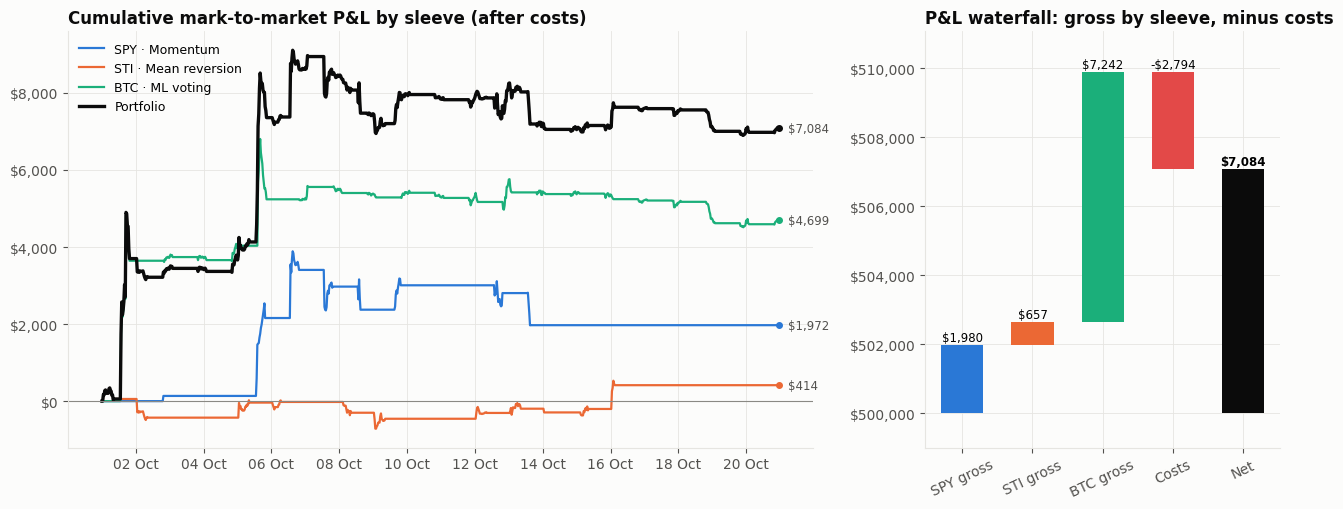

In [28]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [2.1, 1]})
for a in ASSETS:
    ax.plot(idx, pnl[a], color=COLOR[a], label=LABEL[a])
    end_label(ax, idx[-1], pnl[a].iloc[-1], money(pnl[a].iloc[-1]), COLOR[a])
ax.plot(idx, pnl.sum(axis=1), color=INK, lw=2.4, label="Portfolio")
end_label(ax, idx[-1], pnl.sum(axis=1).iloc[-1], money(pnl.sum(axis=1).iloc[-1]), INK)
ax.axhline(0, color=MUTED, lw=0.8); ax.yaxis.set_major_formatter(USD)
ax.set_title("Cumulative mark-to-market P&L by sleeve (after costs)"); ax.legend(loc="upper left")
date_axis(ax)
# waterfall
gross = {a: pnl[a].iloc[-1] + cum_cost[a].iloc[-1] for a in ASSETS}
steps = [("Start", INITIAL, None)] + [(f"{SHORT[a]} gross", gross[a], COLOR[a]) for a in ASSETS] + \
        [("Costs", -cum_cost.iloc[-1].sum(), NEG)]
level = INITIAL
peak = INITIAL
for i, (name, val, c) in enumerate(steps):
    if name == "Start":
        continue
    ax2.bar(i, val, bottom=level, color=c, width=0.6)
    ax2.annotate(money(val), (i, level + max(val, 0)), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
    level += val
    peak = max(peak, level)
ax2.bar(len(steps), level - INITIAL, bottom=INITIAL, color=INK, width=0.6)
ax2.annotate(money(level - INITIAL), (len(steps), level), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, weight="bold")
ax2.set_xticks(range(1, len(steps) + 1), [s[0] for s in steps[1:]] + ["Net"], rotation=25)
ax2.set_ylim(INITIAL - 0.1 * (peak - INITIAL), peak + 0.12 * (peak - INITIAL))
ax2.yaxis.set_major_formatter(USD)
ax2.set_title("P&L waterfall: gross by sleeve, minus costs")
fig.tight_layout(); save(fig, "07a_attribution"); plt.show()

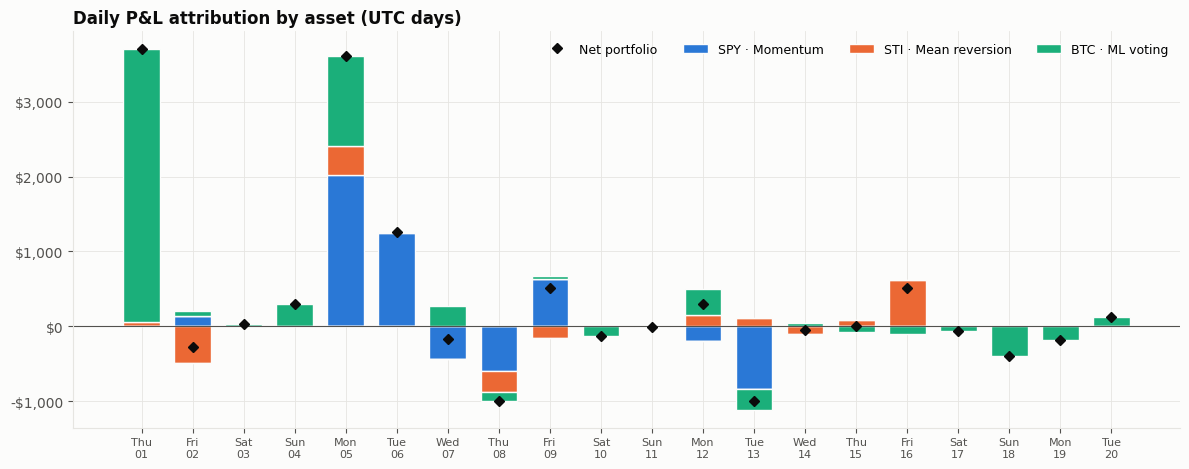

,01 Oct,02 Oct,03 Oct,04 Oct,05 Oct,06 Oct,07 Oct,08 Oct,09 Oct,10 Oct,11 Oct,12 Oct,13 Oct,14 Oct,15 Oct,16 Oct,17 Oct,18 Oct,19 Oct,20 Oct
spy_usd,0,135,0,0,"2,022","1,249",-433,-599,633,0,0,-202,-833,0,0,0,0,0,0,0
sti_es3_sgd,56,-484,0,0,391,16,0,-280,-156,0,0,151,110,-97,90,617,0,0,0,0
btc_usdt,"3,644",72,25,292,"1,205",-7,266,-115,41,-128,-9,344,-280,48,-82,-109,-62,-396,-177,125
Portfolio,"3,700",-277,25,292,"3,618","1,259",-168,-994,518,-128,-9,293,"-1,003",-49,7,509,-62,-396,-177,125


In [29]:
dd_asset = pd.DataFrame({a: pnl[a].resample("1D").last() for a in ASSETS})
dd_asset = dd_asset.diff().fillna(dd_asset.iloc[0])
fig, ax = plt.subplots(figsize=(12, 4.8))
xx = np.arange(len(dd_asset)); bp, bn = np.zeros(len(xx)), np.zeros(len(xx))
for a in ASSETS:
    v_ = dd_asset[a].values; p_, n_ = np.clip(v_, 0, None), np.clip(v_, None, 0)
    ax.bar(xx, p_, bottom=bp, color=COLOR[a], width=0.72, edgecolor=SURF, lw=1, label=LABEL[a])
    ax.bar(xx, n_, bottom=bn, color=COLOR[a], width=0.72, edgecolor=SURF, lw=1)
    bp += p_; bn += n_
ax.plot(xx, dd_asset.sum(axis=1), "D", color=INK, ms=5, label="Net portfolio", zorder=5)
ax.axhline(0, color=INK2, lw=0.8); ax.yaxis.set_major_formatter(USD)
ax.set_xticks(xx, [d.strftime("%a\n%d") for d in dd_asset.index], fontsize=8)
ax.set_title("Daily P&L attribution by asset (UTC days)"); ax.legend(ncol=4, loc="upper right")
fig.tight_layout(); save(fig, "07b_daily_attribution"); plt.show()
display(dd_asset.assign(Portfolio=dd_asset.sum(axis=1)).set_axis([d.strftime("%d %b") for d in dd_asset.index])
        .T.style.format("{:,.0f}").background_gradient(cmap=DIVERGING, axis=None, vmin=-dd_asset.abs().values.max(), vmax=dd_asset.abs().values.max())
        .set_caption("Daily P&L by asset (USD)"))

### 7.2 Strategy versus buy-and-hold
Each sleeve's return on its capital compared with holding the same asset with the same capital over
the window.

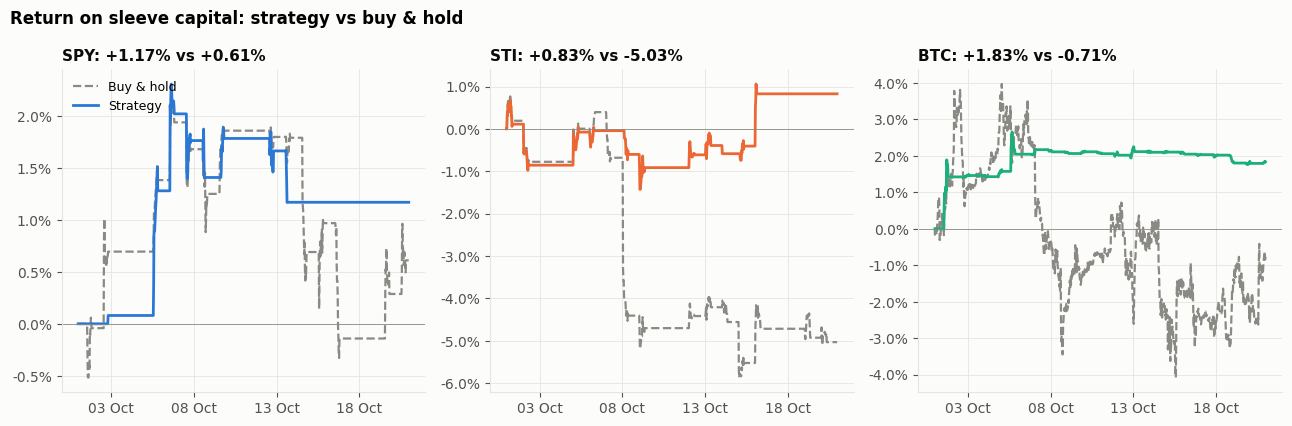

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharey=False)
for ax, a in zip(axes, ASSETS):
    s = series[f"{SHORT[a]} sleeve"]
    b = with_start(sleeve_cap[a] * bh[a], sleeve_cap[a])
    ax.plot(b.index, 100 * (b / b.iloc[0] - 1), color=MUTED, ls="--", label="Buy & hold")
    ax.plot(s.index, 100 * (s / s.iloc[0] - 1), color=COLOR[a], lw=2, label="Strategy")
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.set_title(f"{SHORT[a]}: {100 * (s.iloc[-1] / s.iloc[0] - 1):+.2f}% vs {100 * (b.iloc[-1] / b.iloc[0] - 1):+.2f}%", fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}%"))
    date_axis(ax, 5)
axes[0].legend(loc="upper left")
fig.suptitle("Return on sleeve capital: strategy vs buy & hold", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "07c_sleeve_vs_bh"); plt.show()

### 7.3 Sleeve scorecard

In [31]:
rows = {}
for a in ASSETS:
    f = fills[fills["asset"].eq(a)]; t = trades[trades["asset"].eq(a)]
    m = table.loc[f"{SHORT[a]} sleeve"]
    rows[LABEL[a]] = {
        "Net P&L (USD)": pnl[a].iloc[-1], "Costs (USD)": cum_cost[a].iloc[-1],
        "Sleeve capital (USD)": sleeve_cap[a], "Return on sleeve": m["Total Return"],
        "Buy & hold return": bh[a].iloc[-1] - 1, "Excess vs B&H": m["Total Return"] - (bh[a].iloc[-1] - 1),
        "Contribution to portfolio": pnl[a].iloc[-1] / INITIAL, "Ann. vol (sleeve)": m["Annual Volatility"],
        "Max DD (sleeve)": m["Max Drawdown"], "Time in market": held[a].mean(),
        "Orders": len(f), "Round trips": len(t), "Win rate": (t["net_pnl"] > 0).mean() if len(t) else np.nan,
        "Avg hold (h)": t["holding_hours"].mean() if len(t) else np.nan,
        "Profit factor": (t.loc[t.net_pnl > 0, "net_pnl"].sum() / -t.loc[t.net_pnl < 0, "net_pnl"].sum())
        if (t.net_pnl < 0).any() else np.nan,
    }
scorecard = pd.DataFrame(rows)
pct_rows = ["Return on sleeve", "Buy & hold return", "Excess vs B&H", "Contribution to portfolio",
            "Ann. vol (sleeve)", "Max DD (sleeve)", "Time in market", "Win rate"]
sty = scorecard.style.format("{:,.0f}", subset=pd.IndexSlice[["Net P&L (USD)", "Costs (USD)", "Sleeve capital (USD)", "Orders", "Round trips"], :])
sty = sty.format("{:+.2%}", subset=pd.IndexSlice[pct_rows, :]).format("{:.1f}", subset=pd.IndexSlice[["Avg hold (h)", "Profit factor"], :], na_rep="–")
display(sty.set_caption("Per-asset scorecard"))
scorecard.to_csv(FIG_DIR / "per_asset_scorecard.csv")
table.to_csv(FIG_DIR / "metrics_comparison.csv")

,SPY · Momentum,STI · Mean reversion,BTC · ML voting
Net P&L (USD),"1,972",414,"4,699"
Costs (USD),8,243,"2,543"
Sleeve capital (USD),"168,887","50,000","256,113"
Return on sleeve,+1.17%,+0.83%,+1.83%
Buy & hold return,+0.61%,-5.03%,-0.71%
Excess vs B&H,+0.56%,+5.86%,+2.55%
Contribution to portfolio,+0.39%,+0.08%,+0.94%
Ann. vol (sleeve),+6.89%,+8.43%,+6.45%
Max DD (sleeve),-1.11%,-2.10%,-0.87%
Time in market,+49.17%,+60.83%,+24.58%


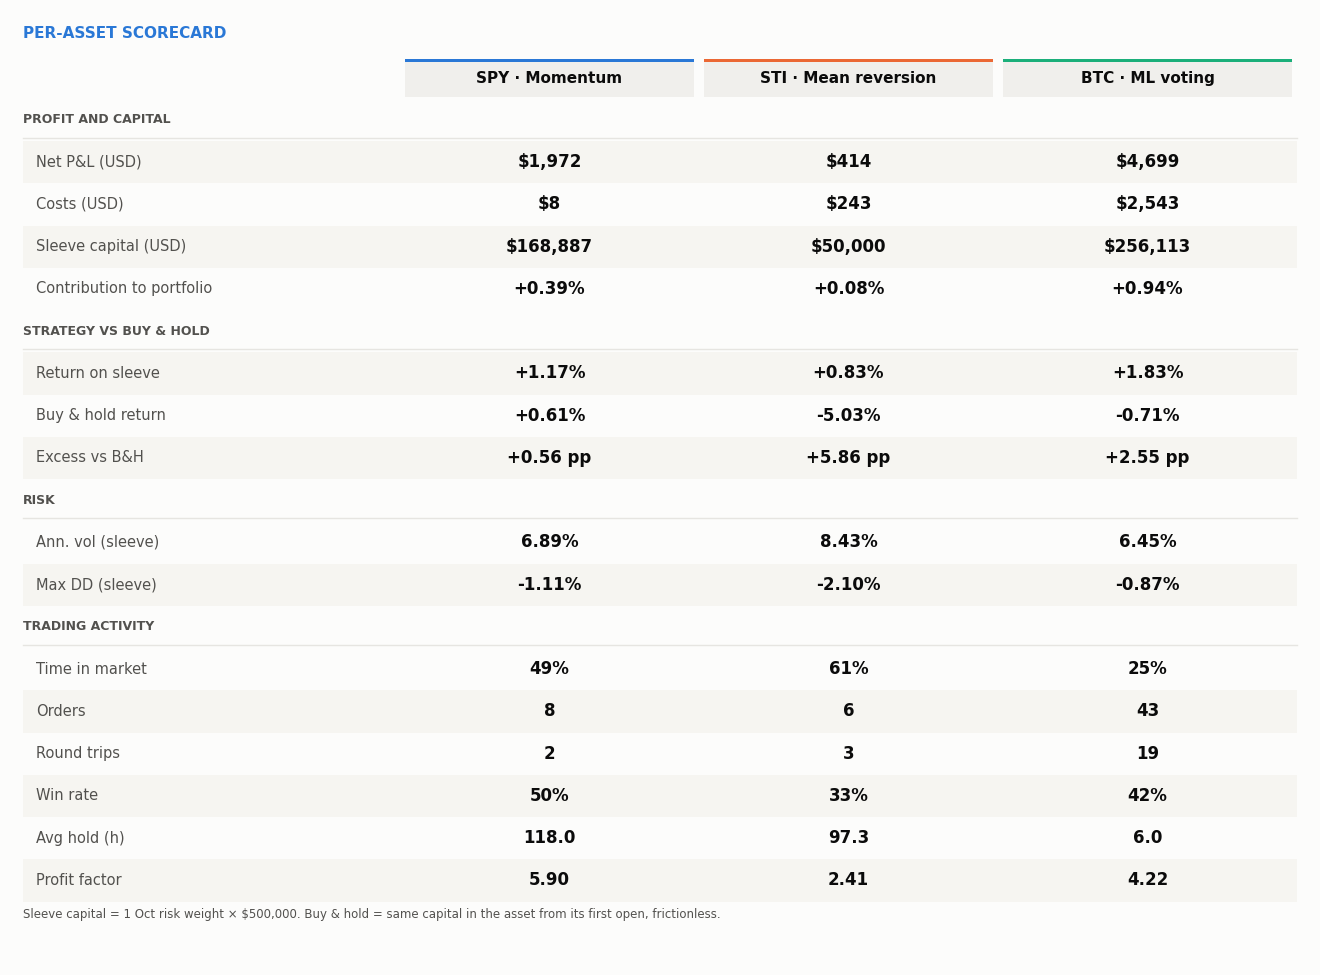

In [32]:
SC_FMT = {"Net P&L (USD)": lambda v: money(v), "Costs (USD)": lambda v: money(v),
          "Sleeve capital (USD)": lambda v: money(v),
          "Return on sleeve": "{:+.2%}".format, "Buy & hold return": "{:+.2%}".format,
          "Excess vs B&H": lambda v: f"{v * 100:+.2f} pp", "Contribution to portfolio": "{:+.2%}".format,
          "Ann. vol (sleeve)": "{:.2%}".format, "Max DD (sleeve)": "{:.2%}".format,
          "Time in market": "{:.0%}".format, "Orders": "{:.0f}".format, "Round trips": "{:.0f}".format,
          "Win rate": "{:.0%}".format, "Avg hold (h)": "{:.1f}".format, "Profit factor": "{:.2f}".format}
sc_cells = pd.DataFrame({c: [SC_FMT[r](scorecard.at[r, c]) if pd.notna(scorecard.at[r, c]) else "–"
                             for r in scorecard.index] for c in scorecard.columns}, index=scorecard.index)

draw_metric_grid(
    sc_cells,
    "Per-asset scorecard",
    [("Profit and capital", ["Net P&L (USD)", "Costs (USD)", "Sleeve capital (USD)", "Contribution to portfolio"]),
     ("Strategy vs buy & hold", ["Return on sleeve", "Buy & hold return", "Excess vs B&H"]),
     ("Risk", ["Ann. vol (sleeve)", "Max DD (sleeve)"]),
     ("Trading activity", ["Time in market", "Orders", "Round trips", "Win rate", "Avg hold (h)", "Profit factor"])],
    GRID_COLORS,
    note="Sleeve capital = 1 Oct risk weight × $500,000. Buy & hold = same capital in the asset from its first open, frictionless.",
    fname="07c_per_asset_scorecard_grid",
)

### 7.4 Capital, risk and P&L shares
Each sleeve's share of average capital deployed, of portfolio risk (covariance contribution of
30-minute P&L to total variance) and of P&L.

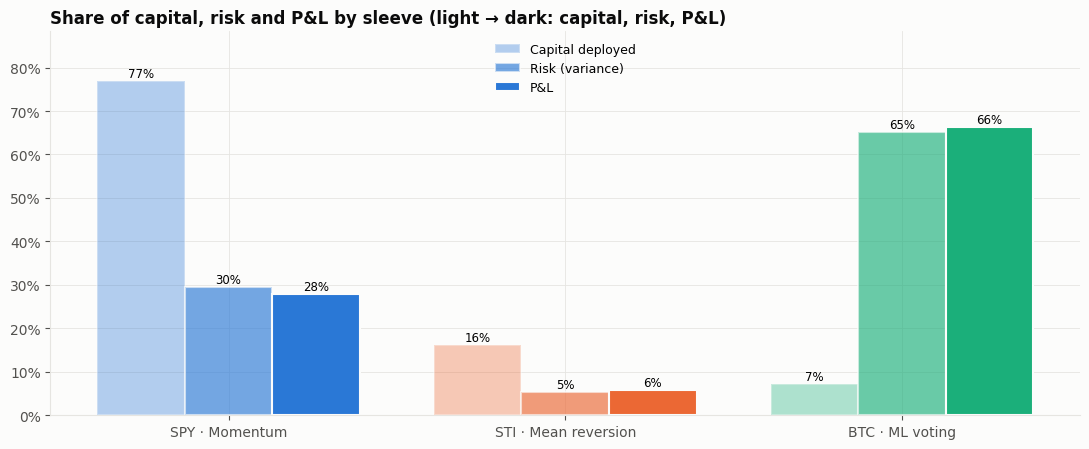

,Capital deployed,Risk (variance),P&L
spy_usd,76.8%,29.5%,27.8%
sti_es3_sgd,16.1%,5.3%,5.8%
btc_usdt,7.1%,65.2%,66.3%


In [33]:
cap_share = mkt_value.abs().mean() / mkt_value.abs().mean().sum()
cov_ = dpnl[ASSETS].cov()
risk_share = cov_.sum(axis=1) / cov_.values.sum()
pnl_share = pnl.iloc[-1] / pnl.iloc[-1].sum()
comp = pd.DataFrame({"Capital deployed": cap_share, "Risk (variance)": risk_share, "P&L": pnl_share}).reindex(ASSETS)
fig, ax = plt.subplots(figsize=(11, 4.6))
xg = np.arange(3); wbar = 0.26
for j, (col, alpha) in enumerate(zip(comp.columns, [0.35, 0.65, 1.0])):
    ax.bar(xg + (j - 1) * wbar, comp[col], width=wbar, color=[COLOR[a] for a in ASSETS], alpha=alpha,
           edgecolor=SURF, lw=1.5, label=col)
    for i, v_ in enumerate(comp[col]):
        ax.annotate(f"{v_:.0%}", (xg[i] + (j - 1) * wbar, v_), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
ax.set_xticks(xg, [LABEL[a] for a in ASSETS]); ax.yaxis.set_major_formatter(PCT(0))
ax.set_title("Share of capital, risk and P&L by sleeve (light → dark: capital, risk, P&L)")
ax.set_ylim(0, comp.values.max() * 1.15)
ax.legend(loc="upper center")
fig.tight_layout(); save(fig, "07d_capital_risk_pnl"); plt.show()
display(comp.style.format("{:.1%}"))

### 7.5 Risk–return profile and diversification

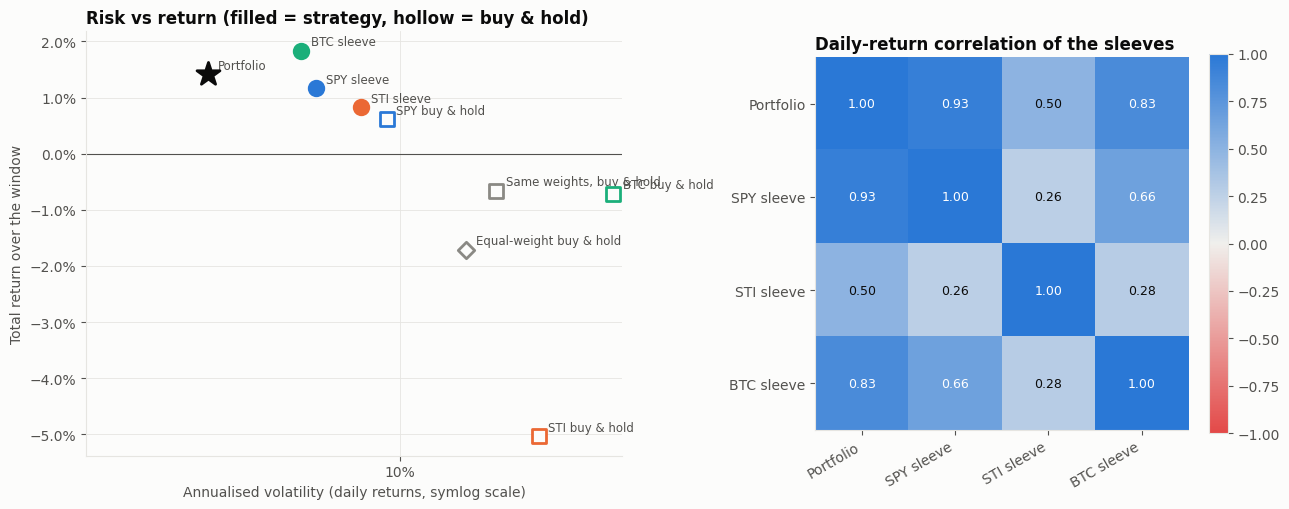

In [34]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
pts = {"Portfolio": (INK, "*", 300), "Same weights, buy & hold": (MUTED, "s", 90), "Equal-weight buy & hold": (MUTED, "D", 70)}
for a in ASSETS:
    pts[f"{SHORT[a]} sleeve"] = (COLOR[a], "o", 110)
    pts[f"{SHORT[a]} buy & hold"] = (COLOR[a], "s", 90)
for name, (c, mk, sz) in pts.items():
    vv, rr = table.at[name, "Annual Volatility"], table.at[name, "Total Return"]
    hollow = "buy & hold" in name
    ax.scatter(vv, rr, s=sz, marker=mk, color=SURF if hollow else c, edgecolor=c, lw=2, zorder=5)
    ax.annotate(name, (vv, rr), xytext=(7, 4), textcoords="offset points", fontsize=8.5, color=INK2)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xscale("symlog", linthresh=0.05)
ax.xaxis.set_major_formatter(PCT(0)); ax.yaxis.set_major_formatter(PCT(1))
ax.set_xlabel("Annualised volatility (daily returns, symlog scale)"); ax.set_ylabel("Total return over the window")
ax.set_title("Risk vs return (filled = strategy, hollow = buy & hold)")
names = ["Portfolio"] + [f"{SHORT[a]} sleeve" for a in ASSETS]
dly = pd.DataFrame({n: series[n].iloc[1:].resample("1D").last().pct_change() for n in names}).dropna()
cm = dly.corr()
im = ax2.imshow(cm, cmap=DIVERGING, vmin=-1, vmax=1); ax2.grid(False)
ax2.set_xticks(range(4), names, rotation=30, ha="right"); ax2.set_yticks(range(4), names)
for i in range(4):
    for j in range(4):
        ax2.text(j, i, f"{cm.iat[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(cm.iat[i, j]) > 0.6 else INK)
ax2.set_title("Daily-return correlation of the sleeves")
fig.colorbar(im, ax=ax2, fraction=0.046)
fig.tight_layout(); save(fig, "07e_risk_return_corr"); plt.show()

## 8. Trades and transaction costs

### 8.1 Completed round trips

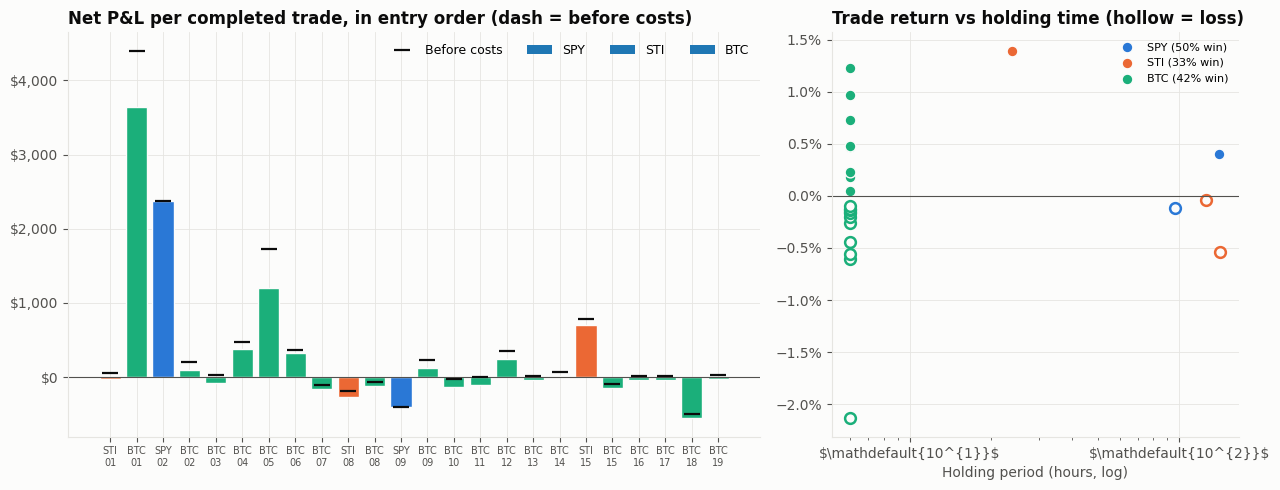

,asset,side,entry_time,exit_time,holding_hours,entry_price,exit_price,pnl_before_costs,fees,net_pnl,return_pct
0,sti_es3_sgd,long,01 Oct 01:00,06 Oct 07:00,126.0,4.496,4.501,59,80,-21,-0.04%
1,btc_usdt,long,01 Oct 13:30,01 Oct 19:30,6.0,"83,476.040","84,455.127","4,399",754,"3,644",+0.97%
2,spy_usd,long,02 Oct 19:30,08 Oct 15:30,140.0,771.403,774.534,"2,379",5,"2,374",+0.40%
3,btc_usdt,long,02 Oct 20:00,03 Oct 02:00,6.0,"84,315.270","84,640.010",199,103,95,+0.18%
4,btc_usdt,short,03 Oct 20:00,04 Oct 02:00,6.0,"84,842.500","84,802.600",24,103,-79,-0.15%
5,btc_usdt,long,04 Oct 20:00,05 Oct 02:00,6.0,"85,428.000","86,218.200",477,104,373,+0.72%
6,btc_usdt,short,05 Oct 14:30,05 Oct 20:30,6.0,"86,282.000","85,708.463","1,721",516,"1,205",+0.47%
7,btc_usdt,short,06 Oct 20:00,07 Oct 02:00,6.0,"85,614.000","84,391.490",372,52,320,+1.23%
8,btc_usdt,long,07 Oct 20:00,08 Oct 02:00,6.0,"83,434.670","83,099.210",-105,52,-157,-0.60%
9,sti_es3_sgd,long,08 Oct 03:00,14 Oct 01:00,142.0,4.318,4.302,-191,81,-272,-0.53%


In [35]:
tt = trades.sort_values("entry_time").reset_index(drop=True)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.7, 1]})
ax.bar(range(len(tt)), tt["net_pnl"], color=[COLOR[a] for a in tt["asset"]], edgecolor=SURF, lw=1)
ax.scatter(range(len(tt)), tt["pnl_before_costs"], marker="_", s=120, color=INK, zorder=5, label="Before costs")
ax.axhline(0, color=INK2, lw=0.8); ax.yaxis.set_major_formatter(USD)
ax.set_xticks(range(len(tt)), [f"{SHORT[a]}\n{t:%d}" for a, t in zip(tt["asset"], tt["entry_time"])], fontsize=7)
ax.set_title("Net P&L per completed trade, in entry order (dash = before costs)")
for a in ASSETS:
    ax.bar([], [], color=COLOR[a], label=SHORT[a])
ax.legend(ncol=4, loc="upper right")
for a in ASSETS:
    t = tt[tt["asset"].eq(a)]
    win = t["net_pnl"] > 0
    ax2.scatter(t.loc[win, "holding_hours"], t.loc[win, "return_pct"], s=60, color=COLOR[a], edgecolor=SURF, label=f"{SHORT[a]} ({win.mean():.0%} win)")
    ax2.scatter(t.loc[~win, "holding_hours"], t.loc[~win, "return_pct"], s=60, color=SURF, edgecolor=COLOR[a], lw=1.8)
ax2.axhline(0, color=INK2, lw=0.8); ax2.set_xscale("log")
ax2.yaxis.set_major_formatter(PCT(1)); ax2.set_xlabel("Holding period (hours, log)")
ax2.set_title("Trade return vs holding time (hollow = loss)"); ax2.legend(fontsize=8)
fig.tight_layout(); save(fig, "08a_trades"); plt.show()
show = tt[["asset", "side", "entry_time", "exit_time", "holding_hours", "entry_price", "exit_price", "pnl_before_costs", "fees", "net_pnl", "return_pct"]]
display(show.style.format({"entry_price": "{:,.3f}", "exit_price": "{:,.3f}", "pnl_before_costs": "{:,.0f}", "fees": "{:,.0f}",
                           "net_pnl": "{:,.0f}", "return_pct": "{:+.2%}", "holding_hours": "{:.1f}",
                           "entry_time": "{:%d %b %H:%M}", "exit_time": "{:%d %b %H:%M}"})
        .bar(subset=["net_pnl"], align="zero", color=[NEG, POS]).set_caption("Completed trades"))

### 8.2 BTC: model signals versus daily fallback
BTC round trips classified by the rule that opened them.

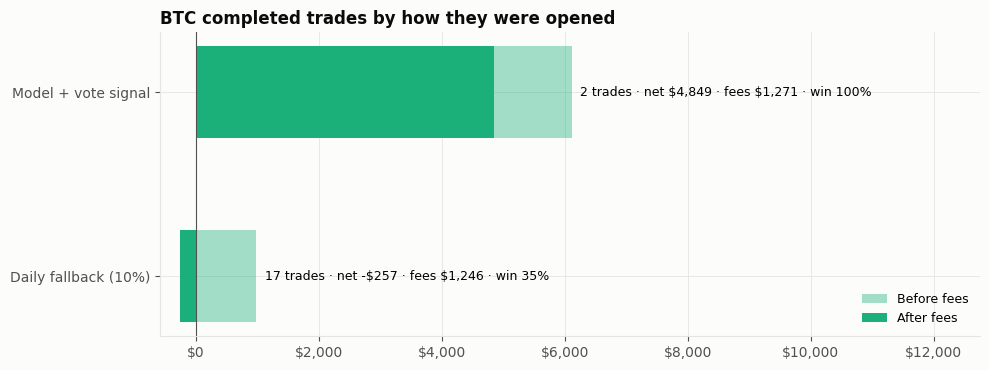

,trades,net_pnl,fees,win_rate,avg_return
type,,,,,
Daily fallback (10%),17,-257,"1,246",35%,-0.12%
Model + vote signal,2,"4,849","1,271",100%,+0.72%


In [36]:
opens = bw[bw["signal_reason"].str.contains("entry|fallback")]["signal_reason"]
bt = tt[tt["asset"].eq("btc_usdt")].copy()
bt["open_reason"] = [opens.loc[:t].iloc[-1] if len(opens.loc[:t]) else "unknown" for t in bt["entry_time"]]
bt["type"] = np.where(bt["open_reason"].str.contains("fallback"), "Daily fallback (10%)", "Model + vote signal")
g = bt.groupby("type").agg(trades=("net_pnl", "size"), net_pnl=("net_pnl", "sum"), fees=("fees", "sum"),
                           win_rate=("net_pnl", lambda s: (s > 0).mean()), avg_return=("return_pct", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.8))
yy = np.arange(len(g))
ax.barh(yy, g["net_pnl"] + g["fees"], color=COLOR["btc_usdt"], alpha=0.4, height=0.5, label="Before fees")
ax.barh(yy, g["net_pnl"], color=COLOR["btc_usdt"], height=0.5, label="After fees")
for i, (n, r) in enumerate(g.iterrows()):
    ax.annotate(f"{int(r.trades)} trades · net {money(r.net_pnl)} · fees {money(r.fees)} · win {r.win_rate:.0%}",
                (max(r.net_pnl + r.fees, r.net_pnl, 0), i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_yticks(yy, g.index); ax.axvline(0, color=INK2, lw=0.8); ax.xaxis.set_major_formatter(USD)
lo_, hi_ = ax.get_xlim(); ax.set_xlim(lo_, hi_ + 0.9 * (hi_ - lo_))
ax.set_title("BTC completed trades by how they were opened"); ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "08b_btc_signal_vs_fallback"); plt.show()
display(g.style.format({"net_pnl": "{:,.0f}", "fees": "{:,.0f}", "win_rate": "{:.0%}", "avg_return": "{:+.2%}"}))

### 8.3 Transaction costs
Commissions per `config/cost_assumptions.json`: SPY at USD 0.0035 per share (IBKR Pro Tiered), STI
at 0.08% with an SGD 2.50 minimum, BTC at 0.10% (Binance). No slippage is applied.

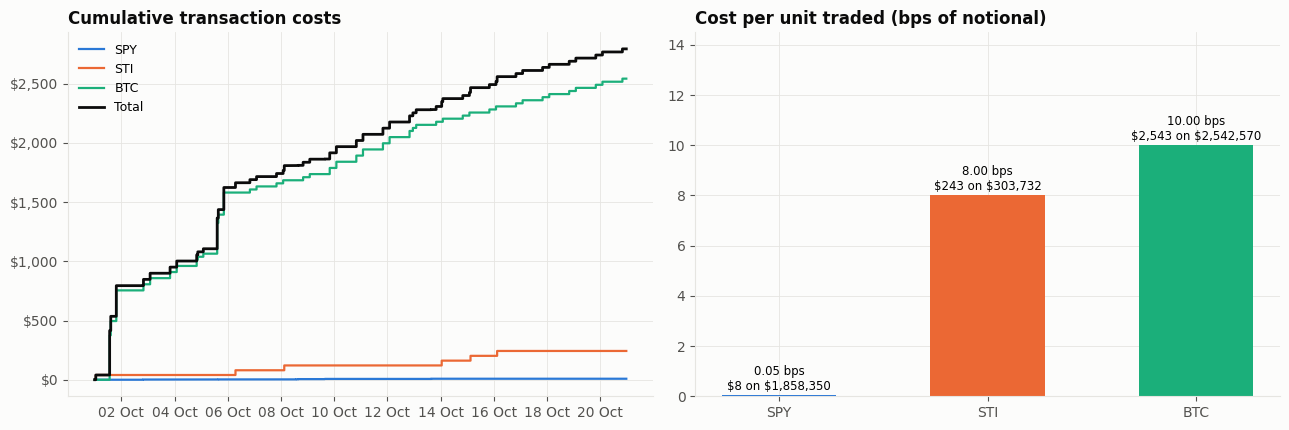

,Notional traded,Cost,bps,Cost / gross P&L
asset,,,,
spy_usd,"1,858,350",8,0.0,0%
sti_es3_sgd,"303,732",243,8.0,37%
btc_usdt,"2,542,570","2,543",10.0,35%


In [37]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
for a in ASSETS:
    ax.step(idx, cum_cost[a], where="post", color=COLOR[a], label=SHORT[a])
ax.step(idx, cum_cost.sum(axis=1), where="post", color=INK, lw=2, label="Total")
ax.yaxis.set_major_formatter(USD); ax.set_title("Cumulative transaction costs"); ax.legend(); date_axis(ax)
cb = pd.DataFrame({"Notional traded": fills.groupby("asset")["notional"].sum(), "Cost": fills.groupby("asset")["total_cost"].sum()}).reindex(ASSETS)
cb["bps"] = cb["Cost"] / cb["Notional traded"] * 1e4
cb["Cost / gross P&L"] = cb["Cost"] / pd.Series(gross)
ax2.bar([SHORT[a] for a in ASSETS], cb["bps"], color=[COLOR[a] for a in ASSETS], width=0.55)
for i, (a, r) in enumerate(cb.iterrows()):
    ax2.annotate(f"{r.bps:.2f} bps\n{money(r.Cost)} on {money(r['Notional traded'])}", (i, r.bps), xytext=(0, 4),
                 textcoords="offset points", ha="center", fontsize=8.5)
ax2.set_ylim(0, cb["bps"].max() * 1.45); ax2.set_title("Cost per unit traded (bps of notional)")
fig.tight_layout(); save(fig, "08c_costs"); plt.show()
display(cb.style.format({"Notional traded": "{:,.0f}", "Cost": "{:,.0f}", "bps": "{:.1f}", "Cost / gross P&L": "{:.0%}"}))

## 9. Summary

### 9.1 Key performance metrics
The most informative measures for this evaluation: the result against a passive mix of the same assets, the drivers behind it, and the statistical confidence it supports.

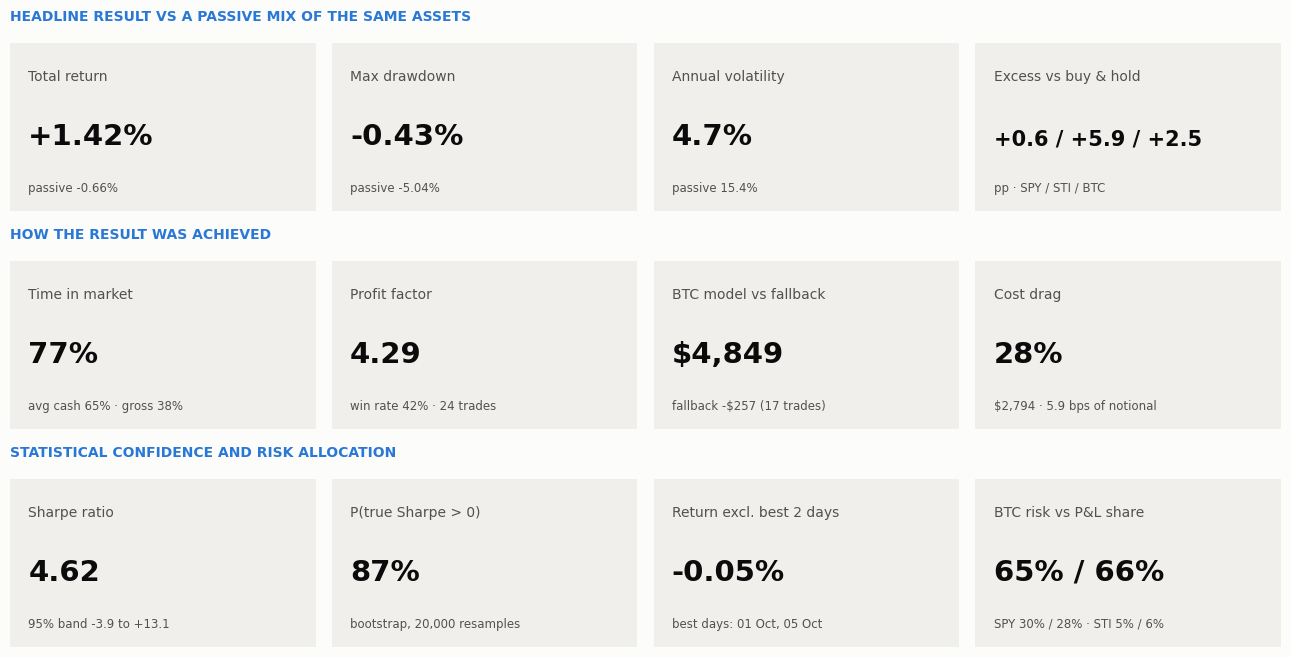

Group,Metric,Value,Context
Headline,Total return,+1.42%,Same-weights buy & hold -0.66%
Headline,Max drawdown,-0.43%,Same-weights buy & hold -5.04%
Headline,Annual volatility,4.68%,Same-weights buy & hold 15.35%
Headline,Excess return vs buy & hold · SPY,+0.56 pp,Return on sleeve capital minus asset buy & hold
Headline,Excess return vs buy & hold · STI,+5.86 pp,Return on sleeve capital minus asset buy & hold
Headline,Excess return vs buy & hold · BTC,+2.55 pp,Return on sleeve capital minus asset buy & hold
Drivers,Time in market (any sleeve),77%,"Average cash 65%, average gross exposure 38%"
Drivers,Risk share / P&L share · SPY,30% / 28%,Covariance share of 30-min P&L vs share of net P&L
Drivers,Risk share / P&L share · STI,5% / 6%,Covariance share of 30-min P&L vs share of net P&L
Drivers,Risk share / P&L share · BTC,65% / 66%,Covariance share of 30-min P&L vs share of net P&L


In [38]:
def _metrics(eq):
    return M.compute_metrics(eq, periods_per_year=365, risk_free_rate=RF_SERIES, metric_frequency="daily",
                             drop_incomplete_final_day=True, annualize_by_elapsed_time=True)


km_port, km_bench = _metrics(series["Portfolio"]), _metrics(series["Same weights, buy & hold"])

# Tier 1 — result vs a passive mix of the same assets
excess = {a: (series[f"{SHORT[a]} sleeve"].iloc[-1] / sleeve_cap[a] - 1) - (bh[a].iloc[-1] - 1) for a in ASSETS}

# Tier 2 — how the result was achieved
held_any = (pos != 0).any(axis=1).mean()
cash_avg = (curve["cash"] / curve["equity"]).mean()
gross_avg = curve["gross_exposure"].mean()
wins, losses = trades.loc[trades["net_pnl"] > 0, "net_pnl"].sum(), -trades.loc[trades["net_pnl"] < 0, "net_pnl"].sum()
profit_factor = wins / losses if losses > 0 else np.nan
win_rate = (trades["net_pnl"] > 0).mean()
d_pnl = pnl.diff().fillna(pnl.iloc[0])
risk_share = d_pnl[ASSETS].cov().sum(axis=1) / d_pnl[ASSETS].cov().values.sum()
pnl_share = pnl.iloc[-1] / pnl.iloc[-1].sum()
total_cost = cum_cost.iloc[-1].sum()
gross_pnl = pnl.iloc[-1].sum() + total_cost
cost_bps = total_cost / fills["notional"].sum() * 1e4

btc_win = btc.loc[t0:t1 - pd.Timedelta(minutes=1)]
btc_opens = btc_win[btc_win["signal_reason"].str.contains("entry|fallback")]["signal_reason"]
btc_tr = trades[trades["asset"].eq("btc_usdt")].copy()
btc_tr["fallback"] = [bool(len(btc_opens.loc[:t])) and "fallback" in btc_opens.loc[:t].iloc[-1]
                      for t in btc_tr["entry_time"]]
model_pnl, model_n = btc_tr.loc[~btc_tr["fallback"], "net_pnl"].sum(), int((~btc_tr["fallback"]).sum())
fb_pnl, fb_n = btc_tr.loc[btc_tr["fallback"], "net_pnl"].sum(), int(btc_tr["fallback"].sum())
fb_fees = btc_tr.loc[btc_tr["fallback"], "fees"].sum()

# Tier 3 — statistical confidence
d_ret = M.daily_portfolio_returns(series["Portfolio"])
rf_daily = (1 + RF_SERIES.reindex(RF_SERIES.index.union(d_ret.index)).ffill().reindex(d_ret.index)) ** (1 / 365) - 1
ex = (d_ret - rf_daily).to_numpy()
sr_d = ex.mean() / ex.std(ddof=1)
se_d = math.sqrt((1 + 0.5 * sr_d ** 2) / len(ex))
sr_lo, sr_hi = (sr_d - 1.96 * se_d) * math.sqrt(365), (sr_d + 1.96 * se_d) * math.sqrt(365)
rng = np.random.default_rng(7)
boot_sr = np.array([(lambda x: x.mean() / x.std(ddof=1))(rng.choice(ex, len(ex), replace=True)) for _ in range(20000)])
p_pos = (boot_sr > 0).mean()
d_sorted = d_ret.sort_values(ascending=False)
ex_best2 = (1 + d_sorted.iloc[2:]).prod() - 1
best2 = ", ".join(d.strftime("%d %b") for d in d_sorted.index[:2])

tiers = [
    ("Headline result vs a passive mix of the same assets", [
        ("Total return", f"{km_port['Total Return']:+.2%}", f"passive {km_bench['Total Return']:+.2%}"),
        ("Max drawdown", f"{km_port['Max Drawdown']:.2%}", f"passive {km_bench['Max Drawdown']:.2%}"),
        ("Annual volatility", f"{km_port['Annual Volatility']:.1%}", f"passive {km_bench['Annual Volatility']:.1%}"),
        ("Excess vs buy & hold", " / ".join(f"{excess[a] * 100:+.1f}" for a in ASSETS), "pp · SPY / STI / BTC"),
    ]),
    ("How the result was achieved", [
        ("Time in market", f"{held_any:.0%}", f"avg cash {cash_avg:.0%} · gross {gross_avg:.0%}"),
        ("Profit factor", f"{profit_factor:.2f}", f"win rate {win_rate:.0%} · {len(trades)} trades"),
        ("BTC model vs fallback", f"{money(model_pnl)}", f"fallback {money(fb_pnl)} ({fb_n} trades)"),
        ("Cost drag", f"{total_cost / gross_pnl:.0%}", f"{money(total_cost)} · {cost_bps:.1f} bps of notional"),
    ]),
    ("Statistical confidence and risk allocation", [
        ("Sharpe ratio", f"{km_port['Sharpe Ratio']:.2f}", f"95% band {sr_lo:.1f} to {sr_hi:+.1f}"),
        ("P(true Sharpe > 0)", f"{p_pos:.0%}", "bootstrap, 20,000 resamples"),
        ("Return excl. best 2 days", f"{ex_best2:+.2%}", f"best days: {best2}"),
        ("BTC risk vs P&L share", f"{risk_share['btc_usdt']:.0%} / {pnl_share['btc_usdt']:.0%}",
         f"SPY {risk_share['spy_usd']:.0%} / {pnl_share['spy_usd']:.0%} · STI {risk_share['sti_es3_sgd']:.0%} / {pnl_share['sti_es3_sgd']:.0%}"),
    ]),
]

fig = plt.figure(figsize=(13, 6.6))
for t_i, (tier_title, tiles) in enumerate(tiers):
    top = 1 - t_i * 0.33
    fig.text(0.01, top - 0.02, tier_title.upper(), fontsize=10, weight="bold", color=POS)
    for j, (label, value, sub) in enumerate(tiles):
        ax = fig.add_axes([0.01 + j * 0.2475, top - 0.31, 0.235, 0.255])
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_facecolor(MID)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.text(0.06, 0.78, label, fontsize=10, color=INK2, transform=ax.transAxes)
        ax.text(0.06, 0.40, value, fontsize=21 if len(value) <= 10 else 15, weight="bold", color=INK, transform=ax.transAxes)
        ax.text(0.06, 0.12, sub, fontsize=8.5, color=INK2, transform=ax.transAxes)
save(fig, "09_key_performance_metrics"); plt.show()

key_metrics = pd.DataFrame([
    ("Headline", "Total return", f"{km_port['Total Return']:+.2%}", f"Same-weights buy & hold {km_bench['Total Return']:+.2%}"),
    ("Headline", "Max drawdown", f"{km_port['Max Drawdown']:.2%}", f"Same-weights buy & hold {km_bench['Max Drawdown']:.2%}"),
    ("Headline", "Annual volatility", f"{km_port['Annual Volatility']:.2%}", f"Same-weights buy & hold {km_bench['Annual Volatility']:.2%}"),
    *[("Headline", f"Excess return vs buy & hold · {SHORT[a]}", f"{excess[a] * 100:+.2f} pp", "Return on sleeve capital minus asset buy & hold") for a in ASSETS],
    ("Drivers", "Time in market (any sleeve)", f"{held_any:.0%}", f"Average cash {cash_avg:.0%}, average gross exposure {gross_avg:.0%}"),
    *[("Drivers", f"Risk share / P&L share · {SHORT[a]}", f"{risk_share[a]:.0%} / {pnl_share[a]:.0%}", "Covariance share of 30-min P&L vs share of net P&L") for a in ASSETS],
    ("Drivers", "Profit factor", f"{profit_factor:.2f}", f"Win rate {win_rate:.1%} over {len(trades)} completed trades"),
    ("Drivers", "BTC model-signal trades", money(model_pnl), f"{model_n} trades"),
    ("Drivers", "BTC daily-fallback trades", money(fb_pnl), f"{fb_n} trades, {money(fb_fees)} in fees"),
    ("Drivers", "Transaction costs", money(total_cost), f"{total_cost / gross_pnl:.0%} of gross P&L, {cost_bps:.1f} bps of traded notional"),
    ("Confidence", "Sharpe ratio", f"{km_port['Sharpe Ratio']:.2f}", f"95% band {sr_lo:.1f} to {sr_hi:+.1f} (Lo, 2002)"),
    ("Confidence", "Probability true Sharpe > 0", f"{p_pos:.0%}", "Bootstrap of daily excess returns, 20,000 resamples"),
    ("Confidence", "Return excluding best 2 days", f"{ex_best2:+.2%}", f"Best days: {best2}"),
], columns=["Group", "Metric", "Value", "Context"])
display(key_metrics.style.hide(axis="index").set_caption("Key performance metrics — evaluation period 1–20 Oct 2026"))
key_metrics.to_csv(FIG_DIR / "key_performance_metrics.csv", index=False)

### 9.2 Key Findings

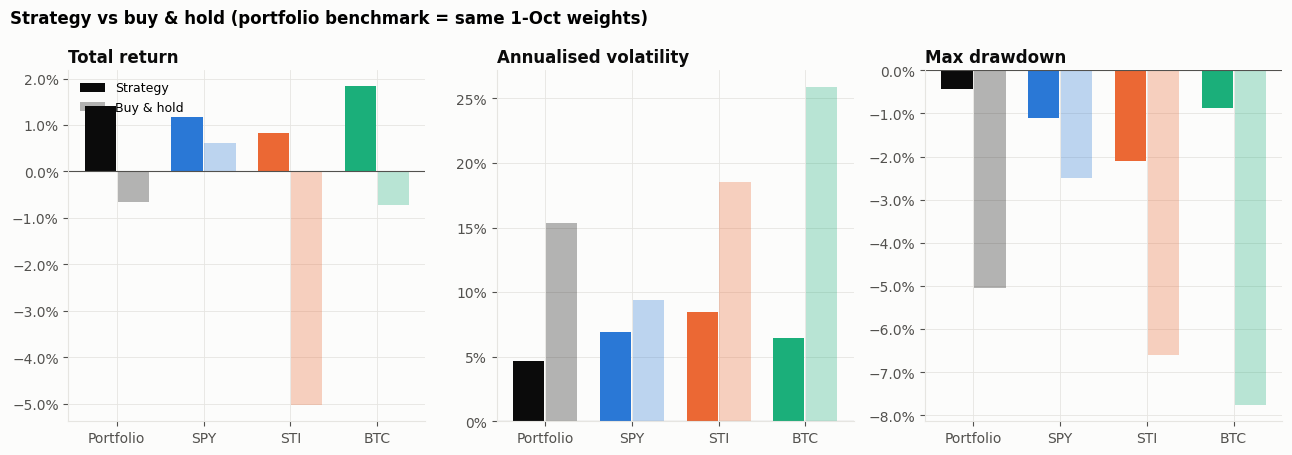

In [39]:
cmp_names = [("Portfolio", "Same weights, buy & hold")] + [(f"{SHORT[a]} sleeve", f"{SHORT[a]} buy & hold") for a in ASSETS]
measures = [("Total Return", "Total return", PCT(1)), ("Annual Volatility", "Annualised volatility", PCT(0)), ("Max Drawdown", "Max drawdown", PCT(1))]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (col, title, fmt_) in zip(axes, measures):
    labels_ = [n[0].replace(" sleeve", "") for n in cmp_names]
    s_vals = [table.at[n[0], col] for n in cmp_names]
    b_vals = [table.at[n[1], col] for n in cmp_names]
    xg = np.arange(len(cmp_names))
    cols = [INK] + [COLOR[a] for a in ASSETS]
    ax.bar(xg - 0.19, s_vals, width=0.36, color=cols, label="Strategy")
    ax.bar(xg + 0.19, b_vals, width=0.36, color=cols, alpha=0.3, label="Buy & hold")
    ax.axhline(0, color=INK2, lw=0.8); ax.yaxis.set_major_formatter(fmt_)
    ax.set_xticks(xg, labels_); ax.set_title(title)
axes[0].legend(loc="upper left")
fig.suptitle("Strategy vs buy & hold (portfolio benchmark = same 1-Oct weights)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "09a_comparative_summary"); plt.show()

In [40]:
p = table.loc["Portfolio"]; b = table.loc["Same weights, buy & hold"]
best = max(ASSETS, key=lambda a: pnl[a].iloc[-1])
lines = [
    f"* **Portfolio:** {money(p['Net P&L (USD)'])} ({p['Total Return']:+.2%}) vs {b['Total Return']:+.2%} for the same weights held passively; "
    f"max drawdown {p['Max Drawdown']:.2%} vs {b['Max Drawdown']:.2%}; annualised vol {p['Annual Volatility']:.1%} vs {b['Annual Volatility']:.1%}.",
    f"* **Largest contributor:** {LABEL[best]} with {money(pnl[best].iloc[-1])} ({pnl[best].iloc[-1] / pnl.iloc[-1].sum():.0%} of P&L).",
] + [
    f"* **{LABEL[a]}:** {money(pnl[a].iloc[-1])} on {money(sleeve_cap[a])} sleeve capital "
    f"({scorecard.at['Return on sleeve', LABEL[a]]:+.2%} vs buy & hold {scorecard.at['Buy & hold return', LABEL[a]]:+.2%}), "
    f"in the market {held[a].mean():.0%} of the time, {int(scorecard.at['Round trips', LABEL[a]])} round trips."
    for a in ASSETS
] + [
    f"* **Costs:** {money(cum_cost.iloc[-1].sum())} in total ({cum_cost.iloc[-1].sum() / sum(gross.values()):.0%} of gross P&L); "
    f"BTC accounts for {cum_cost['btc_usdt'].iloc[-1] / cum_cost.iloc[-1].sum():.0%} of costs; its {int(g.loc['Daily fallback (10%)', 'trades'])} "
    f"fallback trades paid {money(g.loc['Daily fallback (10%)', 'fees'])} in fees and netted {money(g.loc['Daily fallback (10%)', 'net_pnl'])}, "
    f"while {int(g.loc['Model + vote signal', 'trades'])} model-signal trades netted {money(g.loc['Model + vote signal', 'net_pnl'])}.",
    f"* **Concentration:** the best two days ({', '.join(d.strftime('%d %b') for d in srt.head(2).index)}) delivered "
    f"{(1 + srt.head(2)).prod() - 1:+.2%}; the other {len(srt) - 2} days together returned {excl['Excl. best 2']:+.2%}.",
    f"* **Statistical confidence:** Sharpe {exp['Sharpe'].iloc[-1]:.2f} with a 95% band of [{exp['lo'].iloc[-1]:.1f}, {exp['hi'].iloc[-1]:.1f}] "
    f"and a {(boot > 0).mean():.0%} bootstrap probability of a positive true Sharpe: descriptive of this window rather than proof of persistent skill.",
]
display(Markdown("### Key findings\n" + "\n".join(lines)))

### Key findings
* **Portfolio:** $7,084 (+1.42%) vs -0.66% for the same weights held passively; max drawdown -0.43% vs -5.04%; annualised vol 4.7% vs 15.4%.
* **Largest contributor:** BTC · ML voting with $4,699 (66% of P&L).
* **SPY · Momentum:** $1,972 on $168,887 sleeve capital (+1.17% vs buy & hold +0.61%), in the market 49% of the time, 2 round trips.
* **STI · Mean reversion:** $414 on $50,000 sleeve capital (+0.83% vs buy & hold -5.03%), in the market 61% of the time, 3 round trips.
* **BTC · ML voting:** $4,699 on $256,113 sleeve capital (+1.83% vs buy & hold -0.71%), in the market 25% of the time, 19 round trips.
* **Costs:** $2,794 in total (28% of gross P&L); BTC accounts for 91% of costs; its 17 fallback trades paid $1,246 in fees and netted -$257, while 2 model-signal trades netted $4,849.
* **Concentration:** the best two days (01 Oct, 05 Oct) delivered +1.46%; the other 18 days together returned -0.05%.
* **Statistical confidence:** Sharpe 4.62 with a 95% band of [-3.9, 13.1] and a 87% bootstrap probability of a positive true Sharpe: descriptive of this window rather than proof of persistent skill.

## 10. Interactive dashboard
Interactive versions of the key views, exported to
`results/eda_notebook/portfolio_interactive_dashboard.html`.

In [41]:
try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    HAVE_PLOTLY = True
except ImportError:
    HAVE_PLOTLY = False
    print("Plotly is not available; the interactive dashboard is not generated.")

HEX = {**COLOR, "port": INK, "bench": MUTED}


def rgba(hex_, a):
    h = hex_.lstrip("#")
    return f"rgba({int(h[0:2], 16)},{int(h[2:4], 16)},{int(h[4:6], 16)},{a})"


LAYOUT = dict(template="simple_white", paper_bgcolor=SURF, plot_bgcolor=SURF, font=dict(size=12, color=INK),
              hovermode="x unified", margin=dict(l=70, r=30, t=110, b=40),
              title=dict(x=0.01, y=0.985, yanchor="top", font=dict(size=16)),
              legend=dict(orientation="h", yanchor="bottom", y=1.0, x=0, font=dict(size=11)))
RANGE_BUTTONS = dict(x=1, xanchor="right", y=1.0, yanchor="bottom", buttons=[dict(count=1, step="day", stepmode="backward", label="1d"),
                              dict(count=3, step="day", stepmode="backward", label="3d"),
                              dict(count=7, step="day", stepmode="backward", label="1w"),
                              dict(step="all", label="All")])
interactive_figs = []

### 10.1 Portfolio overview
Indexed equity against benchmarks, drawdown, cumulative P&L by sleeve and portfolio weights, with
every order marked.

In [42]:
if HAVE_PLOTLY:
    fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.035,
                        row_heights=[0.38, 0.16, 0.26, 0.20],
                        subplot_titles=("Indexed to 100", "Drawdown from peak", "Cumulative P&L by sleeve (USD, after costs)",
                                        "Portfolio weight by asset"))
    to100 = lambda s: 100 * s / s.iloc[0]  # noqa: E731
    for a in ASSETS:
        s_ = to100(series[f"{SHORT[a]} buy & hold"]).iloc[1:]
        fig.add_trace(go.Scatter(x=s_.index, y=s_, name=f"{SHORT[a]} buy & hold", line=dict(color=HEX[a], width=1),
                                 visible="legendonly", hovertemplate="%{y:.2f}"), 1, 1)
    for name, dash in (("Equal-weight buy & hold", "dot"), ("Same weights, buy & hold", "dash")):
        s_ = to100(series[name]).iloc[1:]
        fig.add_trace(go.Scatter(x=s_.index, y=s_, name=name, line=dict(color=MUTED, dash=dash, width=1.6),
                                 hovertemplate="%{y:.2f}"), 1, 1)
    s_ = to100(series["Portfolio before costs"]).iloc[1:]
    fig.add_trace(go.Scatter(x=s_.index, y=s_, name="Portfolio before costs", line=dict(color=INK, dash="dot", width=1),
                             hovertemplate="%{y:.2f}"), 1, 1)
    s_ = to100(series["Portfolio"]).iloc[1:]
    fig.add_trace(go.Scatter(x=s_.index, y=s_, name="Portfolio (net)", line=dict(color=INK, width=3),
                             hovertemplate="%{y:.3f}"), 1, 1)
    f_ = fills.copy()
    f_["lvl"] = 100 * equity.reindex(f_["timestamp"]).values / INITIAL
    f_["side"] = np.where(f_["qty"] > 0, "BUY", "SELL")
    for a in ASSETS:
        ff = f_[f_["asset"].eq(a)]
        fig.add_trace(go.Scatter(
            x=ff["timestamp"], y=ff["lvl"], mode="markers", name=f"{SHORT[a]} orders",
            marker=dict(color=HEX[a], size=9, symbol=np.where(ff["qty"] > 0, "triangle-up", "triangle-down"),
                        line=dict(color=SURF, width=1)),
            customdata=np.stack([ff["side"], ff["qty"].abs(), ff["ref_price"], ff["total_cost"]], axis=1),
            hovertemplate=f"{SHORT[a]} " + "%{customdata[0]} %{customdata[1]:,.4f} @ $%{customdata[2]:,.2f}"
                          "<br>cost $%{customdata[3]:,.2f}<extra></extra>"), 1, 1)
    for name, col, dash in (("Portfolio", NEG, "solid"), ("Same weights, buy & hold", MUTED, "dash")):
        d_ = 100 * M.drawdown_series(series[name]).iloc[1:]
        fig.add_trace(go.Scatter(x=d_.index, y=d_, name=f"Drawdown · {name}", line=dict(color=col, dash=dash, width=1.4),
                                 fill="tozeroy" if name == "Portfolio" else None, fillcolor=rgba(NEG, 0.15),
                                 showlegend=False, hovertemplate="%{y:.2f}%"), 2, 1)
    for a in ASSETS:
        fig.add_trace(go.Scatter(x=idx, y=pnl[a], name=f"P&L · {SHORT[a]}", line=dict(color=HEX[a], width=1.8),
                                 showlegend=False, hovertemplate="$%{y:,.0f}"), 3, 1)
    fig.add_trace(go.Scatter(x=idx, y=pnl.sum(axis=1), name="P&L · Portfolio", line=dict(color=INK, width=2.6),
                             showlegend=False, hovertemplate="$%{y:,.0f}"), 3, 1)
    for a in ASSETS:
        fig.add_trace(go.Scatter(x=idx, y=100 * weights[a], name=f"Weight · {SHORT[a]}", line=dict(color=HEX[a], width=1),
                                 fill="tozeroy", fillcolor=rgba(HEX[a], 0.35), showlegend=False,
                                 hovertemplate="%{y:.1f}%"), 4, 1)
    fig.update_layout(**{**LAYOUT, "margin": dict(l=70, r=30, t=150, b=40)}, height=1080,
                      title_text="Portfolio explorer — 1 to 20 Oct 2026 (UTC)")
    fig.update_layout(legend=dict(y=1.035))
    fig.update_yaxes(ticksuffix="%", row=2, col=1); fig.update_yaxes(tickprefix="$", row=3, col=1)
    fig.update_yaxes(ticksuffix="%", row=4, col=1)
    fig.update_xaxes(rangeselector=RANGE_BUTTONS, row=1, col=1)
    fig.update_xaxes(rangeslider=dict(visible=True, thickness=0.05), row=4, col=1)
    interactive_figs.append(("Portfolio explorer", fig)); fig.show()

### 10.2 Sleeve detail
Price and executions, the strategy's decision variable with its thresholds, and sleeve P&L against
buy-and-hold of the same capital.

In [43]:
if HAVE_PLOTLY:
    fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06, row_heights=[0.42, 0.28, 0.30],
                        subplot_titles=("Price (USD) and executions", "Decision variable", "Sleeve P&L vs buy & hold (USD)"))
    counts = []
    for a in ASSETS:
        n0 = len(fig.data)
        vis = a == "spy_usd"
        px_ = decisions[decisions["instrument_id"].eq(a)].set_index("timestamp")["close_usd"]
        held_ = pos[a].reindex(px_.index).fillna(0)
        fig.add_trace(go.Scatter(x=px_.index, y=px_, name=f"{SHORT[a]} price", line=dict(color=HEX[a], width=1.4),
                                 visible=vis, hovertemplate="$%{y:,.2f}"), 1, 1)
        fig.add_trace(go.Scatter(x=px_.index, y=px_.where(held_ != 0), name="while holding", mode="lines",
                                 line=dict(color=INK, width=3), visible=vis, hovertemplate="held"), 1, 1)
        ff = fills[fills["asset"].eq(a)]
        fig.add_trace(go.Scatter(
            x=ff["timestamp"], y=ff["ref_price"], mode="markers", name="orders", visible=vis,
            marker=dict(size=10, color=np.where(ff["qty"] > 0, POS, NEG),
                        symbol=np.where(ff["qty"] > 0, "triangle-up", "triangle-down"), line=dict(color=SURF, width=1)),
            customdata=np.stack([np.where(ff["qty"] > 0, "BUY", "SELL"), ff["qty"].abs(), ff["total_cost"]], axis=1),
            hovertemplate="%{customdata[0]} %{customdata[1]:,.4f}<br>cost $%{customdata[2]:,.2f}<extra></extra>"), 1, 1)
        if a == "btc_usdt":
            g_ = (bw["p_up"] + bw["p_down"])
            fig.add_trace(go.Scatter(x=bw.index, y=g_, name="volatility gauge", line=dict(color=INK, width=1.2),
                                     visible=vis, hovertemplate="%{y:.2f}"), 2, 1)
            fig.add_trace(go.Scatter(x=bw.index, y=bw["vote_score"] / 10, name="vote score ÷ 10",
                                     line=dict(color=HEX[a], width=1, shape="hv"), visible=vis,
                                     hovertemplate="%{y:.1f}"), 2, 1)
            th = [(0.35, "gauge threshold 0.35"), (0.2, "vote ±2 (÷10)"), (-0.2, "vote ±2 (÷10)")]
        else:
            sf_ = strategy_frame(a).loc[t0:]
            col_ = "momentum_return" if a == "spy_usd" else "mean_reversion_z_score"
            lab_ = "16h trailing return" if a == "spy_usd" else "z-score"
            fig.add_trace(go.Scatter(x=sf_.index, y=sf_[col_], name=lab_, line=dict(color=HEX[a], shape="hv"),
                                     visible=vis, hovertemplate="%{y:.4f}"), 2, 1)
            pr = strat_cfg[a]["parameters"]
            th = ([(pr["entry_threshold"], "entry"), (pr["exit_threshold"], "exit")] if a == "spy_usd"
                  else [(pr["entry_z_score"], "entry"), (pr["exit_z_score"], "exit")])
        for y_, lab in th:
            fig.add_trace(go.Scatter(x=[idx[0], idx[-1]], y=[y_, y_], name=lab, mode="lines", visible=vis,
                                     line=dict(color=MUTED, dash="dash", width=1), hoverinfo="skip"), 2, 1)
        b_ = sleeve_cap[a] * (bh[a] - 1)
        fig.add_trace(go.Scatter(x=idx, y=b_, name="buy & hold, same capital", line=dict(color=MUTED, dash="dash"),
                                 visible=vis, hovertemplate="$%{y:,.0f}"), 3, 1)
        fig.add_trace(go.Scatter(x=idx, y=pnl[a], name="strategy P&L", line=dict(color=HEX[a], width=2.4),
                                 visible=vis, hovertemplate="$%{y:,.0f}"), 3, 1)
        counts.append((n0, len(fig.data)))
    buttons = []
    for a, (lo_, hi_) in zip(ASSETS, counts):
        v = [lo_ <= i < hi_ for i in range(len(fig.data))]
        buttons.append(dict(label=LABEL[a], method="update", args=[{"visible": v}, {"title.text": f"Asset drill-down — {LABEL[a]}"}]))
    fig.update_layout(**LAYOUT, height=900, title_text=f"Asset drill-down — {LABEL['spy_usd']}",
                      updatemenus=[dict(buttons=buttons, x=1, xanchor="right", y=1.0, yanchor="bottom")])
    fig.update_yaxes(tickprefix="$", row=1, col=1); fig.update_yaxes(tickprefix="$", row=3, col=1)
    fig.update_xaxes(rangeselector=RANGE_BUTTONS, row=1, col=1)
    interactive_figs.append(("Asset drill-down", fig)); fig.show()

### 10.3 Daily attribution and trade timeline

In [44]:
if HAVE_PLOTLY:
    fig = make_subplots(rows=2, cols=1, vertical_spacing=0.12, row_heights=[0.5, 0.5],
                        subplot_titles=("Daily P&L by asset (USD, UTC days)", "Completed trades: entry → exit (blue = gain, red = loss)"))
    for a in ASSETS:
        fig.add_trace(go.Bar(x=dd_asset.index, y=dd_asset[a], name=SHORT[a], marker_color=HEX[a],
                             hovertemplate="$%{y:,.0f}"), 1, 1)
    fig.add_trace(go.Scatter(x=dd_asset.index, y=dd_asset.sum(axis=1), name="Net portfolio", mode="markers+lines",
                             line=dict(color=INK, width=1), marker=dict(symbol="diamond", size=8),
                             hovertemplate="$%{y:,.0f}"), 1, 1)
    ymap = {a: i for i, a in enumerate(ASSETS)}
    for _, t in tt.iterrows():
        c_ = POS if t["net_pnl"] > 0 else NEG
        fig.add_trace(go.Scatter(
            x=[t["entry_time"], t["exit_time"]], y=[SHORT[t["asset"]]] * 2, mode="lines+markers",
            line=dict(color=c_, width=9), marker=dict(size=6, color=c_), showlegend=False,
            hovertemplate=(f"{SHORT[t['asset']]} {t['side']}<br>{t['entry_time']:%d %b %H:%M} → {t['exit_time']:%d %b %H:%M}"
                           f"<br>net {money(t['net_pnl'])} ({t['return_pct']:+.2%}), fees {money(t['fees'])}<extra></extra>")), 2, 1)
    fig.update_layout(**{**LAYOUT, "hovermode": "closest"}, barmode="relative", height=760,
                      title_text="Daily attribution and trade timeline")
    fig.update_yaxes(tickprefix="$", row=1, col=1)
    fig.update_yaxes(categoryorder="array", categoryarray=[SHORT[a] for a in ASSETS][::-1], row=2, col=1)
    interactive_figs.append(("Daily attribution and trades", fig)); fig.show()

### 10.4 P&L by day and hour

In [45]:
if HAVE_PLOTLY:
    fig = go.Figure()
    views = {"Portfolio": tot, **{SHORT[a]: dpnl[a] for a in ASSETS}}
    for k, (name, ser) in enumerate(views.items()):
        h_ = ser.groupby([ser.index.date, ser.index.hour]).sum().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
        vmax = float(np.abs(h_.values).max()) or 1.0
        fig.add_trace(go.Heatmap(z=h_.values, x=[f"{h:02d}:00" for h in range(24)],
                                 y=[pd.Timestamp(d).strftime("%a %d %b") for d in h_.index],
                                 colorscale=[[0, NEG], [0.5, MID], [1, POS]], zmin=-vmax, zmax=vmax, visible=k == 0,
                                 colorbar=dict(title="USD"), hovertemplate="%{y} %{x} UTC<br>$%{z:,.0f}<extra></extra>"))
    buttons = [dict(label=n, method="update", args=[{"visible": [j == k for j in range(len(views))]},
                                                     {"title.text": f"P&L by day × hour (UTC) — {n}"}])
               for k, n in enumerate(views)]
    fig.update_layout(**{**LAYOUT, "hovermode": "closest"}, height=650, title_text="P&L by day × hour (UTC) — Portfolio",
                      yaxis=dict(autorange="reversed"), xaxis_title="Hour (UTC; SGT = UTC+8)",
                      updatemenus=[dict(buttons=buttons, x=1, xanchor="right", y=1.0, yanchor="bottom")])
    interactive_figs.append(("P&L heatmap", fig)); fig.show()

### 10.5 Export

In [46]:
if HAVE_PLOTLY and interactive_figs:
    p_, b_ = table.loc["Portfolio"], table.loc["Same weights, buy & hold"]
    head = (f"<h1>Three-asset portfolio — evaluation period 1–20 Oct 2026</h1>"
            f"<p class='sub'>Net P&amp;L <b>{money(p_['Net P&L (USD)'])}</b> ({p_['Total Return']:+.2%}) · "
            f"same weights buy &amp; hold {b_['Total Return']:+.2%} · max drawdown {p_['Max Drawdown']:.2%} · "
            f"Sharpe {exp['Sharpe'].iloc[-1]:.2f} (95% band {exp['lo'].iloc[-1]:.1f} to {exp['hi'].iloc[-1]:.1f}) · "
            f"costs {money(cum_cost.iloc[-1].sum())}. Times are UTC. Risk-free rate: U.S. Treasury 3-month yield.</p>")
    parts = []
    for i, (title, f) in enumerate(interactive_figs):
        parts.append(f"<section><h2>{title}</h2>" + f.to_html(full_html=False, include_plotlyjs="inline" if i == 0 else False)
                     + "</section>")
    html = ("<!doctype html><html><head><meta charset='utf-8'><meta name='viewport' content='width=device-width, initial-scale=1'>"
            "<title>Portfolio Evaluation Dashboard</title><style>"
            f"body{{font-family:system-ui,-apple-system,Segoe UI,sans-serif;background:{SURF};color:{INK};margin:0 auto;max-width:1300px;padding:16px}}"
            f"h1{{font-size:24px;margin:8px 0}} h2{{font-size:18px;margin:28px 0 4px}} .sub{{color:{INK2};line-height:1.5}}"
            "section{border-top:1px solid #e6e5e1;padding-top:8px}</style></head><body>"
            + head + "".join(parts) + "</body></html>")
    out_html = FIG_DIR / "portfolio_interactive_dashboard.html"
    out_html.write_text(html, encoding="utf-8")
    print(f"Interactive dashboard exported: {out_html.relative_to(PROJECT_ROOT).as_posix()} ({out_html.stat().st_size / 1e6:.1f} MB)")

Interactive dashboard exported: results/eda_notebook/portfolio_interactive_dashboard.html (5.9 MB)
